# 32 Einspeisung, Rohrbaum und Nachbarvergleich

Teil 7: Netz

**Worum es geht**
- Wo speist das Netz ein? Schätzung aus dem Vorlauf: Er kühlt entlang der Rohre ab.
- Mit dem Erzeuger als Quelle die Leitungen ausrichten und einen Rohrbaum bauen: für jedes Haus der kürzeste Rohrweg vom Erzeuger.
- Liegt eine Abweichung am einzelnen Haus oder am Netz? Dazu werden Häuser mit ihren Nachbarn im Rohrbaum verglichen.
- Prüfung gegen die Begehungslabels und Export der Daten für ein mögliches GNN (Notebook 39).

**Daten**
- liest: `daten_cache/paket.pkl` aus Notebook 31, `data/processed/modell_labels.csv`, Außentemperatur über `src/weather.py`
- schreibt: `rohrbaum.png`, `rohrbaum_karte.html`, `fernwaerme_dashboard_rohrbaum.html`, `daten_cache/gnn_daten.npz`; der Dashboard-Export schreibt dabei `fernwaerme_dashboard.html` neu
- vorher ausführen: Notebook 31 (Paket), Notebook 25 (Labels)
- Ausgaben und Dateien enthalten Adressen. Sie bleiben intern.

**Code**
- Rohrnetz und Dashboard in `notebooks/dashboard_export.py`, Wetter in `src/weather.py`. Die Analysen stehen im Notebook.

## 1 Daten laden und Rohrnetz berechnen

- Pakete laden und die Objekte aus Notebook 31 holen.
- Der Dashboard-Export läuft mit, auch wenn das Dashboard nicht gebraucht wird. Er berechnet das Rohrnetz `Gp` und die Zuordnung der Häuser zum nächsten Rohrpunkt `snap`.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import time
import sys
import re
import os
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import geopandas as gpd
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from pyproj import Transformer
from scipy.spatial import cKDTree
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
import folium
from pyproj import Transformer
from branca.colormap import linear
import runpy



In [2]:
#vorher Notebook 31 ausführen

ORDNER = None      #Pfad eintragen, falls die Suche nichts findet

def finde_cache():
    hier = Path.cwd().resolve()
    kandidaten = [hier / "daten_cache", hier.parent / "daten_cache", *sorted(hier.parent.glob("*/daten_cache"))]
    for k in kandidaten:
        if (k / "paket.pkl").exists():
            return k

print("Arbeitsordner dieses Notebooks:", Path.cwd().resolve(), flush=True)
ORDNER = Path(ORDNER) if ORDNER else finde_cache()
if ORDNER is None or not (ORDNER / "paket.pkl").exists():
    raise SystemExit("paket.pkl nicht gefunden. Zelle 1 im alten Notebook ausführen und den Pfad aus der Zeile "
                     "'Gespeichert in ...' oben bei ORDNER eintragen.")
print("Lade aus:", ORDNER, flush=True)

paket = pd.read_pickle(ORDNER / "paket.pkl")
globals().update(paket)

for pfad in (ORDNER.parent, Path(".").resolve()):
    if str(pfad) not in sys.path:
        sys.path.insert(0, str(pfad))
norm_z = lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0")

print("Geladen:", ", ".join(paket))
print(f"Zähler mit Zeitreihe: {len(serien)} | Nodes im Graph: {G.number_of_nodes()} | Kanten: {G.number_of_edges()} | "
      f"Nodes mit Position: {len(pos)}")
fehlt = [n for n in ("serien", "knoten", "G", "pos", "roh", "linien", "kml_linien") if n not in globals()]
print("Für den Dashboard-Export fehlt:", fehlt or "nichts")

Arbeitsordner dieses Notebooks: /Users/ivelinayaneva/projektseminar/notebooks


Lade aus: /Users/ivelinayaneva/projektseminar/notebooks/daten_cache


Geladen: serien, knoten, G, pos, roh, linien, kml_linien, geschaetzt
Zähler mit Zeitreihe: 84 | Nodes im Graph: 111 | Kanten: 111 | Nodes mit Position: 111
Für den Dashboard-Export fehlt: nichts


In [3]:
%run -i dashboard_export.py

Hintergrund: 109 Gebäudelinien (Typ 6), 743 Rohrplan-Linien (Shapefile und KML)


Kanten auf Rohren: 106 von 111 | zu weit vom Rohrnetz: 0 | ohne Rohrverbindung: 5 (diese bleiben gerade Linien)
Geschrieben: /Users/ivelinayaneva/projektseminar/notebooks/fernwaerme_dashboard.html  (10.6 MB)
Zeitraum: 2024-01-01 00:00:00 bis 2025-05-31 23:00:00 (12408 Stunden)
Häuser mit Zeitreihe: 79 | Nodes: 111 | Kanten: 111
Graph ist ohne Kreise: True | Quellen: 8
WARNUNG: 11247 Werte lagen außerhalb des Speicherbereichs und wurden gekappt.
Startzeitpunkt im Dashboard: 2024-01-30 08:00:00
Datei im Browser öffnen (Doppelklick). Karte und Hintergrundkacheln brauchen Internet (Leaflet und Webkarte Bayern).
Hintergrund oben rechts in der Karte umschaltbar. OpenStreetMap geht nur, wenn die Datei über einen lokalen Server geöffnet wird:
  Terminal im Ordner der Datei:  python -m http.server 8000   dann im Browser  http://localhost:8000/fernwaerme_dashboard.html
Achtung: Die Datei enthält Adressen und Zählerdaten. Nicht weitergeben.


/Users/ivelinayaneva/projektseminar/notebooks/dashboard_export.py:139: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  cand = np.asarray(idx.month.isin([12, 1, 2]) & (idx.hour == 8) & (idx.dayofweek < 5))


- Geladen: 84 Zähler mit Zeitreihe, 111 Nodes und 111 Kanten (mit dem Erzeuger aus Notebook 31).
- 106 von 111 Kanten liegen auf Rohren.

## 2 Schätzung der Einspeisestelle aus dem Vorlauf

- Idee: Der Vorlauf kühlt entlang der Leitung durch Wärmeverluste ab. Häuser nahe der Einspeisung bekommen im Mittel etwas wärmeres Wasser.
- Gesucht ist der Punkt im Rohrnetz, zu dem diese Abstufung am besten passt.
- Voraussetzung: Der Dashboard-Export aus Abschnitt 1 ist gelaufen. Er liefert das Rohrnetz `Gp` (Rohrplan in Stücken von ca. 2 m) und die Zuordnung der Häuser `snap`.

Grenzen der Schätzung:
- Gefunden wird der Punkt, an dem die gemessenen Häuser „anfangen“, nicht zwingend die Heizzentrale.
- Mehrere Einspeisepunkte lassen sich nicht trennen.
- Der Vorlaufunterschied ist klein. Stichleitungen mit wenig Durchfluss kühlen aus und verzerren.
- Das Ergebnis ist eine Schätzung, kein Messwert.

### 2.1 Rechnung

- Pro Haus: Vorlauf nur aus der Heizsaison (Dezember bis Februar) und nur aus Stunden mit Durchfluss. Je Stunde wird das Mittel aller Häuser abgezogen. Übrig bleibt die mittlere Abweichung `delta` in K.
- Pro Haus und Netzpunkt: Abstand entlang der Rohre (kürzester Weg).
- Pro Netzpunkt: Rangkorrelation (Spearman) zwischen `delta` und Abstand. An der echten Einspeisung ist sie stark negativ.
- Zufallsvergleich: Häuser 300-mal vertauschen. Ein Signal gibt es nur, wenn der echte Wert klar besser ist als die 5-%-Grenze.
- Ausgabe: die 5 besten Punkte (mindestens 50 m auseinander) mit Vorlaufverlust je 100 m und Gegenprobe mit der Kantendatei (`kanten_stimmen` = Kanten, die vom Punkt wegzeigen). Die Karte zeigt, wie eindeutig die Lage ist.

Häuser: 79 | Stunden: 6389 | Spanne der Abweichung: -10.61 bis 5.56 K


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3259308229.py:21: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  t = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)



Beste Korrelation: -0.70 | bei vertauschten Häusern erreicht man zufällig: -0.13 (Median), -0.28 (5%-Grenze)


,rang,korrelation,K_pro_100m,lat,lon,naechster_node,abstand_zum_node_m,kanten_stimmen,kanten_widersprechen
0,1,-0.70,-1.36,49.797846,10.347358,Nelkenstraße 2,39.0,59,52
1,2,-0.69,-1.21,49.797454,10.346929,Erzeuger (Annahme),21.0,58,53
2,3,-0.69,-1.20,49.796964,10.347096,Erzeuger (Annahme),38.0,58,53
3,4,-0.68,-1.06,49.797233,10.346308,Hans-Zander-Weg 14,16.0,57,54
4,5,-0.68,-0.77,49.797611,10.344753,Rosenstraße 9,8.0,53,58


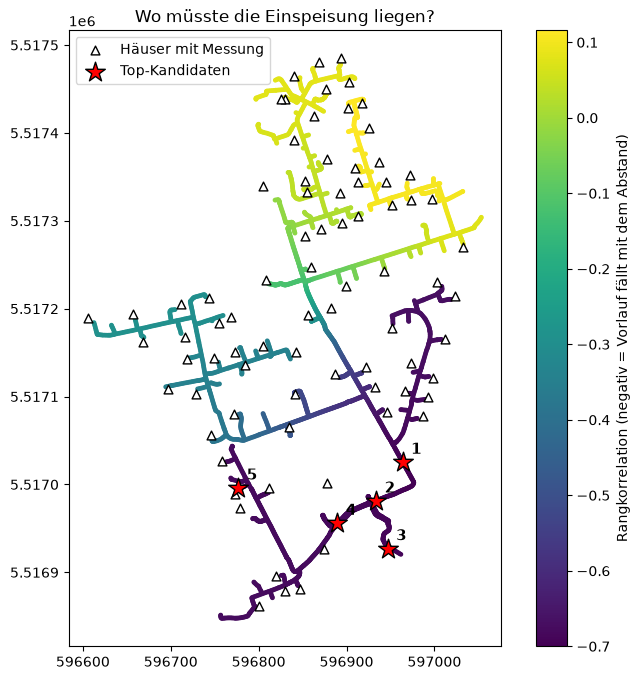

In [4]:


MIN_FLUSS = 40               #l/h
MONATE = [12, 1, 2]
MIN_HAEUSER_STUNDE = 20      #Stunden mit weniger Häusern werden nicht benutzt
MIN_STUNDEN = 200            #Häuser mit weniger Stunden werden nicht benutzt
ABSTAND_M = 50               #Kandidaten für die Top-Liste müssen so weit auseinander liegen

if "Gp" not in globals() or "snap" not in globals():
    raise SystemExit("Gp/snap fehlen: erst den Dashboard-Export (%run -i dashboard_export.py) laufen lassen.")
if not isinstance(xy, np.ndarray):
    raise SystemExit("`xy` wurde überschrieben (z. B. von der Graph-Zeichenzelle): Dashboard-Export erneut laufen lassen.")

nz = norm_z if "norm_z" in globals() else (lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0"))
zaehler_von = {r.edge_node: [nz(z) for z in str(r.zaehler).split(",") if nz(z)] for r in knoten.itertuples()}

spalten = {}
for r in knoten.itertuples():
    if r.edge_node not in nid:
        continue
    ds = [serien[z] for z in zaehler_von.get(r.edge_node, []) if z in serien]
    if ds:
        t = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)
        spalten[r.edge_node] = t[t.index.month.isin(MONATE)]
T = pd.DataFrame(spalten)
T = T[T.notna().sum(axis=1) >= MIN_HAEUSER_STUNDE]
abw = T.sub(T.mean(axis=1), axis=0)
delta = abw.mean()[abw.notna().sum() >= MIN_STUNDEN]
haeuser = list(delta.index)
print(f"Häuser: {len(haeuser)} | Stunden: {len(T)} | Spanne der Abweichung: {delta.min():.2f} bis {delta.max():.2f} K")

#Rohrabstand von jedem Haus zu jedem Punkt im Rohrnetz
V = list(Gp.nodes)
vi = {v: i for i, v in enumerate(V)}
D = np.full((len(haeuser), len(V)), np.inf)
for k, h in enumerate(haeuser):
    for v, x in nx.single_source_dijkstra_path_length(Gp, snap[nid[h]], weight="len").items():
        D[k, vi[v]] = x
ok = np.isfinite(D).all(axis=0)
Dk = D[:, ok]
Vk = [V[i] for i in np.where(ok)[0]]

#an der Quelle fällt der Vorlauf mit dem Abstand (negativ)
rd0 = rankdata(delta.values) - (len(delta) + 1) / 2
RD0 = rankdata(Dk, axis=0) - (len(delta) + 1) / 2
nenner = np.sqrt((rd0 ** 2).sum() * (RD0 ** 2).sum(axis=0))
score = (rd0[:, None] * RD0).sum(axis=0) / nenner

rng = np.random.default_rng(1)
zufall = [((rng.permutation(rd0)[:, None] * RD0).sum(axis=0) / nenner).min() for _ in range(300)]

#Top-Kandidaten, räumlich getrennt
xyv = np.array(Vk)
top = []
for i in np.argsort(score):
    if all(np.hypot(*(xyv[i] - xyv[j])) > ABSTAND_M for j in top):
        top.append(i)
    if len(top) == 5:
        break

G0 = G_orig if "G_orig" in globals() else G
namen = [n for n in nodes]
xy_n = np.array([xy[nid[n]] for n in namen])
zeilen = []
for rang, i in enumerate(top, 1):
    d = nx.single_source_dijkstra_path_length(Gp, Vk[i], weight="len")
    stimmt = widerspricht = 0
    for u, v in G0.edges:
        if u in nid and v in nid and snap[nid[u]] in d and snap[nid[v]] in d:
            if d[snap[nid[u]]] <= d[snap[nid[v]]]:
                stimmt += 1
            else:
                widerspricht += 1
    nah = int(np.argmin(np.hypot(*(xy_n - xyv[i]).T)))
    lon, lat = tr.transform(*Vk[i])
    zeilen.append({"rang": rang, "korrelation": round(score[i], 2),
                   "K_pro_100m": round(np.polyfit(Dk[:, i], delta.values, 1)[0] * 100, 2),
                   "lat": round(lat, 6), "lon": round(lon, 6),
                   "naechster_node": str(roh.get(namen[nah], namen[nah])),
                   "abstand_zum_node_m": round(float(np.hypot(*(xy_n[nah] - xyv[i]))), 0),
                   "kanten_stimmen": stimmt, "kanten_widersprechen": widerspricht})
erg = pd.DataFrame(zeilen)
print(f"\nBeste Korrelation: {score.min():.2f} | bei vertauschten Häusern erreicht man zufällig: "
      f"{np.median(zufall):.2f} (Median), {np.quantile(zufall, 0.05):.2f} (5%-Grenze)")
display(erg)

#Karte: Farbe = Korrelation, wenn die Quelle dort läge
fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(xyv[:, 0], xyv[:, 1], c=score, s=6, cmap="viridis")
hx = np.array([xy[nid[h]] for h in haeuser])
ax.scatter(hx[:, 0], hx[:, 1], marker="^", c="white", edgecolors="black", s=40, label="Häuser mit Messung")
ax.scatter(xyv[top, 0], xyv[top, 1], marker="*", c="red", s=220, edgecolors="black", label="Top-Kandidaten")
for rang, i in enumerate(top, 1):
    ax.annotate(str(rang), xyv[i], xytext=(6, 6), textcoords="offset points", fontsize=11, weight="bold")
ax.set_aspect("equal"); ax.legend(loc="best")
plt.colorbar(sc, label="Rangkorrelation (negativ = Vorlauf fällt mit dem Abstand)")
ax.set_title("Wo müsste die Einspeisung liegen?")
plt.show()

- Beste Rangkorrelation −0,70. Bei vertauschten Häusern liegt die 5-%-Grenze bei −0,28. Das Signal ist deutlich.
- Die 5 besten Punkte liegen dicht beieinander (−0,68 bis −0,70) und zeigen 0,77 bis 1,36 K Vorlaufverlust je 100 m Rohr.
- Auf Rang 2 und 3 liegen Punkte beim Erzeuger-Knoten aus Notebook 31. Die Schätzung passt also zur Annahme aus dem Wärmenetzplan.
- Die Gegenprobe mit der Kantendatei ist schwach: Nur 53 bis 59 von 111 Kanten zeigen vom Punkt weg.

## 3 Erzeuger als Quelle festlegen und Leitungen ausrichten

- Laut Expertenwissen ist der Knoten „Erzeuger (Annahme)“ die Einspeisung. Der Node mit der Adresse des Erzeugers wird mit ihm zusammengeführt.
- Jede Leitung zeigt danach vom näheren zum weiter entfernten Knoten (gezählt in Leitungen bis zum Erzeuger, bei Gleichstand entscheidet der Name).
- Kontrolle: Wie viele Leitungen wurden umgedreht, welche Knoten sind nicht erreichbar, welche haben keine eingehende Leitung?
- Vorher den Dashboard-Export ausführen, damit das Netz im Ausgangszustand ist.

In [5]:
QUELLE = "Erzeuger (Annahme)"   #von Experten bestätigt
ADRESSE = "hans-zander-weg 14"  #Node mit der echten Adresse des Erzeugers (Spalte "node")
QUELLE_KOORD = None             #optional fest (lat, lon), None = Position aus den Daten

if QUELLE not in G:
    raise SystemExit(f"'{QUELLE}' fehlt im Netz: Dashboard-Export erneut laufen lassen.")

#Adress-Node in den Erzeuger einbauen, Position des Erzeugers bleibt
if ADRESSE in G:
    roh[QUELLE] = f"Erzeuger ({roh.get(ADRESSE, ADRESSE)})"
    G = nx.contracted_nodes(G, QUELLE, ADRESSE, self_loops=False, copy=True)
    pos.pop(ADRESSE, None)
    print(f"'{ADRESSE}' mit '{QUELLE}' zusammengeführt")
if QUELLE_KOORD is not None:
    pos[QUELLE] = tuple(QUELLE_KOORD)
print("Position Erzeuger:", pos[QUELLE])

G_orig = G.copy()

#Abstand jedes Nodes zur Quelle (in Kanten)
U = G_orig.to_undirected()
print("Anschluss:", sorted(U[QUELLE], key=str))
tiefe = nx.single_source_shortest_path_length(U, QUELLE)

G_neu = nx.DiGraph()
G_neu.add_nodes_from(G_orig.nodes(data=True))
gedreht = 0
for u, v, d in G_orig.edges(data=True):
    if u in tiefe and v in tiefe:
        a, b = (u, v) if (tiefe[u], str(u)) <= (tiefe[v], str(v)) else (v, u)
        gedreht += (a, b) != (u, v)
    else:
        a, b = u, v
    G_neu.add_edge(a, b, **d)
G = G_neu

print(f"{gedreht} von {G_orig.number_of_edges()} Kanten gedreht")
print("nicht erreichbar:", [n for n in G_orig if n not in tiefe])
print("Nodes ohne eingehende Kante:", [n for n in G if G.in_degree(n) == 0])

'hans-zander-weg 14' mit 'Erzeuger (Annahme)' zusammengeführt
Position Erzeuger: (49.79730660186304, 10.347117955779149)
Anschluss: ['hans-zander-weg 1', 'hans-zander-weg 12']
54 von 111 Kanten gedreht
nicht erreichbar: []
Nodes ohne eingehende Kante: ['Erzeuger (Annahme)']


- 54 von 111 Kanten wurden umgedreht.
- Alle Knoten sind vom Erzeuger aus erreichbar. Nur der Erzeuger hat keine eingehende Kante.

### 3.1 Plausibilitätstest: Stimmt die Fließrichtung?

- Das Wasser kühlt auf dem Weg ab, also sollte der Vorlauf in Pfeilrichtung sinken.
- Je Leitung mit Messungen an beiden Enden: Median von „Vorlauf am Anfang minus Vorlauf am Ende“. Nur Durchfluss ab 20 l/h, November bis März, mindestens 100 gemeinsame Stunden. Unter 0,5 K gilt als unklar.
- Vergleich A (Richtung wie in der Datei) gegen B (Richtung vom Erzeuger weg). Hat B mehr passende Leitungen, stützen die Messdaten die Expertenangabe.
- Die 10 verdächtigsten Leitungen in B sind Hinweise auf mögliche Fehler im Netzmodell, z. B. falsche Anschlüsse, fehlende Leitungen oder vertauschte Zähler.

In [6]:
MIN_FLUSS = 20
MONATE = [11, 12, 1, 2, 3]
MIN_STUNDEN = 100
SCHWELLE_K = 0.5

nz = norm_z if "norm_z" in globals() else (lambda s: "".join(ch for ch in str(s) if ch.isdigit()).lstrip("0"))
zaehler_von = {r.edge_node: [nz(z) for z in str(r.zaehler).split(",") if nz(z)] for r in knoten.itertuples()}

_cache = {}
def vorlauf(n):
    if n not in _cache:
        ds = [serien[z] for z in zaehler_von.get(n, []) if z in serien]
        if not ds:
            _cache[n] = None
        else:
            f = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)
            _cache[n] = f[f.index.month.isin(MONATE)]
    return _cache[n]

def kantentest(Gx):
    zeilen = []
    for u, v in Gx.edges:
        a, b = vorlauf(u), vorlauf(v)
        if a is None or b is None:
            continue
        d = (a - b).dropna()
        if len(d) >= MIN_STUNDEN:
            zeilen.append({"von": roh.get(u, u), "nach": roh.get(v, v),
                           "stunden": len(d), "median_K": round(d.median(), 2)})
    return pd.DataFrame(zeilen)

ergebnis = {}
for name, Gx in [("A: Dateirichtung", G_orig), ("B: vom Erzeuger weg", G)]:
    t = kantentest(Gx)
    ok = int((t["median_K"] > SCHWELLE_K).sum())
    umg = int((t["median_K"] < -SCHWELLE_K).sum())
    ergebnis[name] = t
    print(f"{name}: bewertet {len(t)} von {Gx.number_of_edges()} Kanten | "
          f"Vorlauf sinkt in Pfeilrichtung: {ok} | steigt: {umg} | unklar: {len(t) - ok - umg}")

print("\nVerdächtigste Kanten in B (Vorlauf steigt am stärksten in Pfeilrichtung):")
display(ergebnis["B: vom Erzeuger weg"].sort_values("median_K").head(10))

A: Dateirichtung: bewertet 56 von 111 Kanten | Vorlauf sinkt in Pfeilrichtung: 22 | steigt: 26 | unklar: 8
B: vom Erzeuger weg: bewertet 56 von 110 Kanten | Vorlauf sinkt in Pfeilrichtung: 26 | steigt: 22 | unklar: 8

Verdächtigste Kanten in B (Vorlauf steigt am stärksten in Pfeilrichtung):


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3523151324.py:16: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  f = pd.concat([d["vor"].where(d["fluss"] > MIN_FLUSS) for d in ds], axis=1).mean(axis=1)


,von,nach,stunden,median_K
24,Magnolienweg 2,Asternweg 37,4693,-5.4
55,Rosenstraße 9,Rosenstraße 8,255,-4.3
9,Asternweg 29,Asternweg 22,3978,-3.1
40,Fliederstraße 25,Fliederstraße 27,2935,-2.7
19,Irisweg 9,Irisweg 9a,4094,-2.2
25,Asternweg 39,Magnolienweg 2,4230,-1.9
32,Blumenstraße 4,Blumenstraße 9,3241,-1.9
43,Fliederstraße 28,Fliederstraße 31,3927,-1.8
28,Tulpenstraße 3,Blütenstraße 14,7169,-1.6
49,Nelkenstraße 5,Nelkenstraße 14,4146,-1.6


- A (Datei): Vorlauf sinkt bei 22 von 56 bewerteten Kanten, steigt bei 26.
- B (vom Erzeuger weg): sinkt bei 26, steigt bei 22. B passt etwas besser zu den Messdaten.
- Der Unterschied ist klein. Auf Ebene der Hauskanten bleibt die Richtung unsicher.

## 4 Erzeuger ans Rohrnetz anbinden

- Den Erzeuger auf den nächsten Rohrpunkt setzen und nur den damit verbundenen Teil des Rohrnetzes nehmen.
- Für jedes Haus: Rohrweg vom Erzeuger bis zur Anschlussstelle und Abstand vom Haus zu dieser Stelle (Anschlussabstand).
- Kontrollen: Häuser ohne Verbindung, sehr große Anschlussabstände, Häuser mit gemeinsamer Anschlussstelle.

In [7]:
QUELLE_POS = pos[QUELLE]   #Position des bestätigten Erzeugers (lat, lon)
t = Transformer.from_crs(4326, 25832, always_xy=True)
qx, qy = t.transform(QUELLE_POS[1], QUELLE_POS[0])
d_q, i_q = cKDTree(np.array(V)).query([qx, qy])
q_v = V[i_q]
print(f"Erzeuger liegt {d_q:.0f} m neben dem nächsten Rohrpunkt")

#Rohrnetzteil, an dem der Erzeuger hängt
teil = Gp.subgraph(nx.node_connected_component(Gp, q_v))
ringe = teil.number_of_edges() - teil.number_of_nodes() + 1
print(f"Rohrnetzteil: {teil.number_of_nodes()} Punkte | unabhängige Ringe: {ringe}")

dq = nx.single_source_dijkstra_path_length(Gp, q_v, weight="len")
haeuser = [n for n in G if n != QUELLE and n in nid]
zeilen = []
for h in haeuser:
    i = nid[h]
    zeilen.append({"haus": roh.get(h, h), "anschluss_m": round(float(dist_[i]), 1),
                   "rohrweg_m": round(dq.get(snap[i], np.nan)), "stelle": snap[i]})
ph = pd.DataFrame(zeilen)

print(f"\nHäuser: {len(ph)} | nicht am Erzeuger-Rohrnetz: {int(ph['rohrweg_m'].isna().sum())}")
print(f"Anschlussabstand: Median {ph['anschluss_m'].median():.0f} m, größter {ph['anschluss_m'].max():.0f} m")
print(f"Häuser an einer gemeinsamen Stelle: {int(ph.duplicated('stelle', keep=False).sum())}")
print("\nGrößte Anschlussabstände (Zuordnung prüfen):")
display(ph.sort_values("anschluss_m", ascending=False).head(10).drop(columns="stelle"))
print("Häuser ohne Verbindung zum Erzeuger:")
display(ph[ph["rohrweg_m"].isna()].drop(columns="stelle"))

Erzeuger liegt 6 m neben dem nächsten Rohrpunkt
Rohrnetzteil: 3803 Punkte | unabhängige Ringe: 2013

Häuser: 109 | nicht am Erzeuger-Rohrnetz: 0
Anschlussabstand: Median 6 m, größter 36 m
Häuser an einer gemeinsamen Stelle: 9

Größte Anschlussabstände (Zuordnung prüfen):


,haus,anschluss_m,rohrweg_m
95,Hans-Zander-Weg 1,36.5,96
23,Mohnweg 19a,20.6,454
103,Rosenstraße 7b,18.9,230
54,Blütenstraße 14,16.0,298
19,Asternweg 22,14.3,483
34,Irisweg 3,14.2,689
49,Fliederstraße 7,13.7,473
104,Rosenstraße 7a,12.7,274
24,Asternweg 25,11.6,418
51,Fliederstraße 11,11.0,412


Häuser ohne Verbindung zum Erzeuger:


,haus,anschluss_m,rohrweg_m


- Der Erzeuger liegt 6 m neben dem nächsten Rohrpunkt.
- Alle 109 Häuser sind mit dem Erzeuger verbunden. Anschlussabstand im Median 6 m, höchstens 36 m.
- 9 Häuser liegen an einer gemeinsamen Anschlussstelle.

## 5 Rohrbaum vom Erzeuger zu allen Häusern

- Für jedes Haus mit Zähler der kürzeste Rohrweg vom Erzeuger. Zusammen ergeben die Wege einen Baum.
- Abschnitte zwischen Erzeuger, Abzweigen und Anschlussstellen, mit Länge und Anzahl der Häuser dahinter.
- Test gegen die Messdaten: Das nächste Haus flussaufwärts sollte wärmeren Vorlauf haben.
- Bild `rohrbaum.png`: je dicker die Linie, desto mehr Häuser dahinter. Vorher die Zelle aus Abschnitt 3.1 ausführen (sie definiert `vorlauf()`).

Häuser mit Zähler: 79 | davon ohne Messdatei: 0 | entfernt (ohne Zähler): 30
Baum: 152 Schlüsselpunkte | 151 Abschnitte | 3804 m Rohr genutzt (von 9577 m im Plan)
Häuser: 79 | Anschlussstellen: 79 | Abzweige: 72

Test 'oberes Haus wärmer': bewertet 38 | ja: 36 | nein: 1 | unklar: 1


,oben,unten,median_K
33,Blütenstraße 15,Blütenstraße 24,-0.6
35,Blütenstraße 15,Blütenstraße 11,-0.3
18,Blütenstraße 14,Fliederstraße 18,0.8
34,Blütenstraße 15,Blütenstraße 20,0.9
10,Asternweg 18,Anemonenweg 2,0.9
15,Blütenstraße 14,Asternweg 27,1.1
31,Blütenstraße 14,Fliederstraße 9,1.2
9,Blütenstraße 14,Anemonenweg 3,1.6
37,Hans-Zander-Weg 8,Hans-Zander-Weg 6,1.6
14,Blütenstraße 14,Asternweg 18,2.2


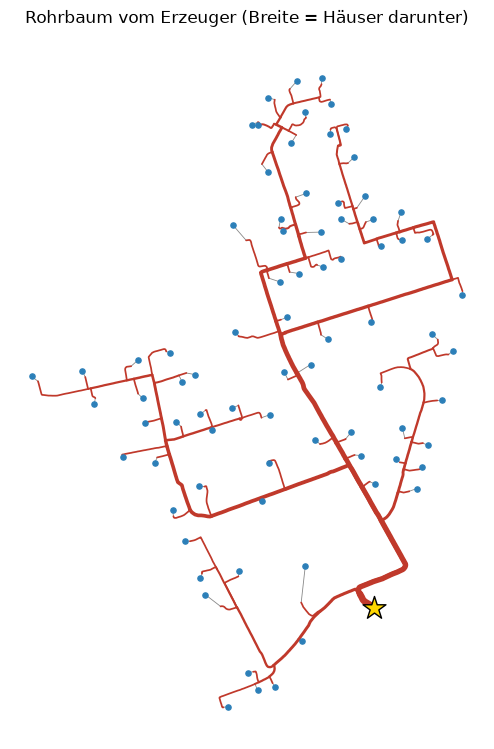

In [8]:
if "vorlauf" not in globals():
    raise SystemExit("Erst die Kantentest-Zelle laufen lassen (sie definiert vorlauf() und MONATE).")

#nur Knoten mit Zähler, der Erzeuger kommt separat dazu
haeuser = [n for n in G if n != QUELLE and n in nid and zaehler_von.get(n)]
ohne_daten = [n for n in haeuser if not any(z in serien for z in zaehler_von[n])]
print(f"Häuser mit Zähler: {len(haeuser)} | davon ohne Messdatei: {len(ohne_daten)} "
      f"| entfernt (ohne Zähler): {sum(1 for n in G if n != QUELLE and n in nid) - len(haeuser)}")
dist_q, pfade = nx.single_source_dijkstra(Gp, q_v, weight="len")

snap_von = {h: snap[nid[h]] for h in haeuser}
parent = {}
for s in set(snap_von.values()):
    p = pfade[s]
    for a, b in zip(p[:-1], p[1:]):
        parent[b] = a
kinder = {}
for b, a in parent.items():
    kinder.setdefault(a, []).append(b)
haus_an = {}
for h, s in snap_von.items():
    haus_an.setdefault(s, []).append(h)

#Schlüsselpunkte: Erzeuger, Anschlussstellen, Verzweigungen
schluessel = {q_v} | set(haus_an) | {v for v, k in kinder.items() if len(k) >= 2}

#Straßenabschnitte zwischen Schlüsselpunkten
T = nx.DiGraph()
for v in schluessel:
    T.add_node(v, art="quelle" if v == q_v else ("haus_stelle" if v in haus_an else "abzweig"))
for v in schluessel - {q_v}:
    weg = [v]
    u = parent[v]
    while u not in schluessel:
        weg.append(u)
        u = parent[u]
    weg.append(u)
    T.add_edge(u, v, laenge=dist_q[v] - dist_q[u], pfad=weg[::-1])
for u, v in T.edges:
    T[u][v]["n_haeuser"] = sum(len(haus_an.get(d, [])) for d in nx.descendants(T, v) | {v})

print(f"Baum: {T.number_of_nodes()} Schlüsselpunkte | {T.number_of_edges()} Abschnitte | "
      f"{sum(d['laenge'] for *_, d in T.edges(data=True)):.0f} m Rohr genutzt (von {sum(d['len'] for *_, d in Gp.edges(data=True)):.0f} m im Plan)")
print(f"Häuser: {len(haeuser)} | Anschlussstellen: {len(haus_an)} | Abzweige: {sum(1 for _, d in T.nodes(data=True) if d['art'] == 'abzweig')}")

#Test: ist das nächste Haus flussaufwärts wärmer?
def oberhaus(s):
    while s != q_v:
        s = next(T.predecessors(s))
        if s in haus_an:
            return haus_an[s]
    return []

zeilen = []
for h, s in snap_von.items():
    for o in oberhaus(s):
        a, b = vorlauf(o), vorlauf(h)
        if a is None or b is None:
            continue
        d = (a - b).dropna()
        if len(d) >= MIN_STUNDEN:
            zeilen.append({"oben": roh.get(o, o), "unten": roh.get(h, h), "median_K": round(d.median(), 2)})
            break
tt = pd.DataFrame(zeilen)
if len(tt):
    ok = int((tt.median_K > SCHWELLE_K).sum()); umg = int((tt.median_K < -SCHWELLE_K).sum())
    print(f"\nTest 'oberes Haus wärmer': bewertet {len(tt)} | ja: {ok} | nein: {umg} | unklar: {len(tt) - ok - umg}")
    display(tt.sort_values("median_K").head(10))

#Bild
fig, ax = plt.subplots(figsize=(11, 9))
mx = max(d["n_haeuser"] for *_, d in T.edges(data=True))
for u, v, d in T.edges(data=True):
    P = np.array(d["pfad"])
    ax.plot(P[:, 0], P[:, 1], color="#c0392b", lw=0.8 + 4 * np.sqrt(d["n_haeuser"] / mx), solid_capstyle="round", zorder=2)
for h in haeuser:
    x, y = xy[nid[h]]
    sx, sy = snap_von[h]
    ax.plot([x, sx], [y, sy], color="#888", lw=0.6, zorder=1)
    ax.scatter([x], [y], s=14, color="#2c7fb8", zorder=3)
ax.scatter([q_v[0]], [q_v[1]], marker="*", s=300, color="gold", edgecolor="k", zorder=4)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Rohrbaum vom Erzeuger (Breite = Häuser darunter)")
plt.savefig("rohrbaum.png", dpi=150, bbox_inches="tight"); plt.show()

- Baum mit 79 Häusern und 72 Abzweigen. Er nutzt 3804 m der 9577 m Rohr im Plan.
- Test „oberes Haus wärmer“: ja bei 36 von 38 bewerteten Paaren, nein bei einem, 1 unklar.
- Der Rohrbaum passt damit gut zum Vorlaufgefälle, deutlich besser als die Kantendatei (Abschnitt 3.1).

## 6 Dashboard auf dem Rohrbaum

- Das Dashboard aus `dashboard_export.py` bekommt den Rohrbaum statt der Kantendatei als Netz. Leitungen und Fließanimation folgen so dem Weg vom Erzeuger über die Straßenleitungen zu den Häusern.
- Der Export läuft in einem eigenen Namensraum, damit die Variablen hier (`nid`, `snap`, `Gp`) erhalten bleiben.
- Ergebnis: `fernwaerme_dashboard_rohrbaum.html`. Das alte Dashboard bleibt erhalten.

In [9]:
PUNKTE_ZEIGEN = False   #Abzweige und Anschlussstellen im Dashboard als graue Punkte zeigen?

t_ll = Transformer.from_crs(25832, 4326, always_xy=True)
def ll_punkt(p):
    lo, la = t_ll.transform(*p)
    return (la, lo)

#Graph fürs Dashboard: Erzeuger -> Rohrbaum-Punkte -> Häuser
name_von = {v: f"Rohr {i}" for i, v in enumerate(T.nodes)}
if set(name_von.values()) & set(G.nodes):
    raise SystemExit("Namenskonflikt: ein Node im Netz heißt schon 'Rohr …'.")
ART = {"quelle": "Einspeisepunkt am Rohr", "abzweig": "Abzweig", "haus_stelle": "Anschlussstelle"}

G_dash = nx.DiGraph()
pos_dash, roh_dash = dict(pos), dict(roh)
for v, d in T.nodes(data=True):
    G_dash.add_node(name_von[v])
    pos_dash[name_von[v]] = ll_punkt(v)
    roh_dash[name_von[v]] = ART[d["art"]]
G_dash.add_edges_from((name_von[u], name_von[v]) for u, v in T.edges)
G_dash.add_edge(QUELLE, name_von[q_v])
for s, hs in haus_an.items():
    for h in hs:
        if h in pos:
            G_dash.add_edge(name_von[s], h)

print(f"Dashboard-Graph: {G_dash.number_of_nodes()} Nodes, {G_dash.number_of_edges()} Kanten | "
      f"Baum: {nx.is_arborescence(G_dash)} | Quellen: {[n for n in G_dash if G_dash.in_degree(n) == 0]}")

#Export in eigenem Namensraum, überschreibt keine Notebook-Variablen
alt = Path("fernwaerme_dashboard.html")
alt_inhalt = alt.read_bytes() if alt.exists() else None

ns = runpy.run_path("dashboard_export.py", init_globals={
    "serien": serien, "knoten": knoten, "G": G_dash, "pos": pos_dash, "roh": roh_dash,
    **{k: globals()[k] for k in ("norm_z", "linien", "kml_linien", "geschaetzt") if k in globals()}})

#unter eigenem Namen speichern, altes Dashboard wiederherstellen
html_ = alt.read_text(encoding="utf-8")
ersetzungen = [
    ("<title>Fernwärme-Dashboard</title>", "<title>Fernwärme-Dashboard (Rohrbaum)</title>"),
    ("<strong>Fernwärme-Dashboard</strong>", "<strong>Fernwärme-Dashboard (Rohrbaum)</strong>"),
    ("Die Pfeilrichtung der Bewegung folgt der Richtung in deiner Kantendatei.",
     "Die Bewegung folgt dem Rohrbaum vom Erzeuger weg."),
    ("Wo mehrere Leitungen in einen Punkt münden, wird die Last gleichmäßig aufgeteilt. Das ist eine Annahme.",
     "Jedes Haus ist über den kürzesten Rohrweg mit dem Erzeuger verbunden. Ringe im Netz werden dabei aufgelöst, das ist eine Annahme."),
    ("Graue Punkte sind Abzweige ohne Zähler. Punkte mit rotem Ring sind Quellen im Graphen. Linien sind Luftlinien, nicht der Rohrverlauf.",
     ("Graue Punkte sind Abzweige und Anschlussstellen am Rohr. " if PUNKTE_ZEIGEN else "")
     + "Der Punkt mit rotem Ring ist der Erzeuger. Leitungen folgen dem Rohrplan, Hausanschlüsse sind gerade Linien."),
]
if not PUNKTE_ZEIGEN:   #Punkte ohne Zähler unsichtbar machen, Erzeuger bleibt sichtbar
    ersetzungen += [
        ("const r = n.m >= 0 ? 6 + 2*Math.min((n.k||1)-1, 3) : 3.5;",
         "const r = n.m >= 0 ? 6 + 2*Math.min((n.k||1)-1, 3) : (n.src ? 7 : 0);"),
        ("{radius:r, weight:n.src ? 3 : 1,",
         "{radius:r, weight:n.src ? 3 : (n.m < 0 ? 0 : 1),"),
        ("if (n.m < 0){ n.mk.setStyle({fillColor:'#aaaaaa', fillOpacity:0.8}); return; }",
         "if (n.m < 0){ return; }"),
    ]
for a, b in ersetzungen:
    if a not in html_:
        print("Hinweis: Textstelle nicht gefunden, Dashboard-Version geändert?", a[:50])
    html_ = html_.replace(a, b)
ziel = Path("fernwaerme_dashboard_rohrbaum.html")
ziel.write_text(html_, encoding="utf-8")
if alt_inhalt is not None:
    alt.write_bytes(alt_inhalt)
else:
    alt.unlink()
print("gespeichert:", ziel.resolve())

Dashboard-Graph: 232 Nodes, 231 Kanten | Baum: True | Quellen: ['Erzeuger (Annahme)']
Hintergrund: 109 Gebäudelinien (Typ 6), 743 Rohrplan-Linien (Shapefile und KML)


Kanten auf Rohren: 151 von 231 | zu weit vom Rohrnetz: 0 | ohne Rohrverbindung: 80 (diese bleiben gerade Linien)
Geschrieben: /Users/ivelinayaneva/projektseminar/notebooks/fernwaerme_dashboard.html  (10.6 MB)
Zeitraum: 2024-01-01 00:00:00 bis 2025-05-31 23:00:00 (12408 Stunden)
Häuser mit Zeitreihe: 79 | Nodes: 232 | Kanten: 231
Graph ist ohne Kreise: True | Quellen: 1
WARNUNG: 11247 Werte lagen außerhalb des Speicherbereichs und wurden gekappt.
Startzeitpunkt im Dashboard: 2024-01-30 08:00:00
Datei im Browser öffnen (Doppelklick). Karte und Hintergrundkacheln brauchen Internet (Leaflet und Webkarte Bayern).
Hintergrund oben rechts in der Karte umschaltbar. OpenStreetMap geht nur, wenn die Datei über einen lokalen Server geöffnet wird:
  Terminal im Ordner der Datei:  python -m http.server 8000   dann im Browser  http://localhost:8000/fernwaerme_dashboard.html
Achtung: Die Datei enthält Adressen und Zählerdaten. Nicht weitergeben.
gespeichert: /Users/ivelinayaneva/projektseminar/notebo

- Dashboard-Graph mit 232 Nodes und 231 Kanten, ein Baum mit einer Quelle.
- 151 von 231 Kanten folgen den Rohren, 80 bleiben gerade Linien.

## 7 Knoten ohne Zähler

- Tabelle aller Knoten: Name, Zähler ja oder nein, Koordinaten.
- Der Erzeuger hat keinen Zähler. Die übrigen Knoten ohne Zähler sind Einträge der Kantendatei ohne Messdaten. Sie fehlen im Rohrbaum und in den Tests.
- Die Kantendatei verbindet Häuser direkt miteinander. Wasser fließt aber von der Straßenleitung ins Haus und zurück, nicht von Haus zu Haus. Für Fließwege gilt deshalb der Rohrbaum.

In [10]:
mit_zaehler = set(knoten["edge_node"])
zeilen = []
for n in G:
    zeilen.append({
        "node": n,
        "anzeige": roh.get(n, n),
        "hat_zaehler": n in mit_zaehler,
        "lat": round(pos[n][0], 6) if n in pos else None,
        "lon": round(pos[n][1], 6) if n in pos else None,
    })
t = pd.DataFrame(zeilen)
print(f"Nodes im Graphen: {len(t)} | mit Zähler: {int(t.hat_zaehler.sum())} | ohne Zähler: {int((~t.hat_zaehler).sum())}")
display(t[~t.hat_zaehler])

Nodes im Graphen: 110 | mit Zähler: 79 | ohne Zähler: 31


,node,anzeige,hat_zaehler,lat,lon
5,ginsterweg 24,Ginsterweg 24,False,49.801550,10.345195
8,ginsterweg 6,Ginsterweg 6,False,49.801408,10.346057
9,ginsterweg 14,Ginsterweg 14,False,49.801408,10.346057
12,anemonenweg 5,Anemonenweg 5,False,49.801092,10.345900
13,anemonenweg 4,Anemonenweg 4,False,49.801025,10.346075
16,mohnweg 21,Mohnweg 21,False,49.800788,10.345561
17,anemonenweg 1,Anemonenweg 1,False,49.800608,10.345974
29,irisweg 8,Irisweg 8,False,49.801378,10.346759
31,irisweg 6,Irisweg 6,False,49.801136,10.346840
32,irisweg 5,Irisweg 5,False,49.801000,10.346761


- 110 Nodes im Graphen, 79 mit Zähler, 31 ohne.

## 8 Messreihen und feste Merkmale je Haus

- Stündliche Messreihen von Januar 2024 bis Mai 2025: Vorlauf, Rücklauf, Spreizung (Vorlauf minus Rücklauf), Durchfluss, Leistung.
- Mehrere Zähler je Haus: Durchfluss und Leistung addiert, Temperaturen gemittelt. Temperaturen nur ab 5 l/h.
- Feste Merkmale je Haus: Rohrweg zum Erzeuger, Abzweige bis zum Erzeuger, Häuser dahinter, Spitzenleistung, Länge der Anschlussleitung.
- Uhrzeit, Wochentag und Tag im Jahr als Sinus und Kosinus, damit z. B. 23 Uhr und 0 Uhr nah beieinander liegen.

In [11]:
START_ = pd.Timestamp(START) if "START" in globals() else pd.Timestamp("2024-01-01 00:00")
ENDE_ = pd.Timestamp(ENDE) if "ENDE" in globals() else pd.Timestamp("2025-05-31 23:00")
zeiten = pd.date_range(START_, ENDE_, freq="h")
FLUSS_MIN = 5.0          #l/h: darunter sind Vorlauf/Rücklauf nicht aussagekräftig
MERKMALE = ["vor", "rueck", "spreizung", "fluss", "leistung"]

hausliste = [h for h in haeuser if any(z in serien for z in zaehler_von.get(h, []))]

def reihe(h):
    ds = []
    for z in zaehler_von[h]:
        if z in serien:
            d = serien[z]
            ds.append(d[~d.index.duplicated()].reindex(zeiten))
    fl = pd.concat([d["fluss"] for d in ds], axis=1).sum(axis=1, min_count=1)
    le = pd.concat([d["leistung"] for d in ds], axis=1).sum(axis=1, min_count=1)
    ok = [d["fluss"] > FLUSS_MIN for d in ds]
    vo = pd.concat([d["vor"].where(o) for d, o in zip(ds, ok)], axis=1).mean(axis=1)
    rk = pd.concat([d["rueck"].where(o) for d, o in zip(ds, ok)], axis=1).mean(axis=1)
    return np.column_stack([vo, rk, vo - rk, fl, le])

X = np.stack([reihe(h) for h in hausliste], axis=1).astype("float32")      #(Zeit, Häuser, Merkmale)
print(f"Zeitreihen: {X.shape[0]} Stunden x {X.shape[1]} Häuser x {X.shape[2]} Merkmale")
print("Anteil gültiger Werte je Merkmal:", dict(zip(MERKMALE, np.round(np.mean(~np.isnan(X), axis=(0, 1)), 2))))

#Knoten: Häuser (0..N-1) + Schlüsselpunkte des Rohrbaums T
N = len(hausliste)
tknoten = list(T.nodes)
tidx = {v: N + i for i, v in enumerate(tknoten)}

def unter(v):
    return sum(len(haus_an.get(d, [])) for d in nx.descendants(T, v) | {v})

statisch = np.zeros((N + len(tknoten), 5), dtype="float32")   #rohrweg_m, tiefe, haeuser_unter, leistung_p99, anschluss_m
for i, h in enumerate(hausliste):
    s = snap_von[h]
    statisch[i] = [dist_q.get(s, np.nan), len(nx.ancestors(T, s)), 1,
                   np.nanpercentile(X[:, i, 4], 99) if np.isfinite(X[:, i, 4]).any() else np.nan,
                   float(dist_[nid[h]])]
for v in tknoten:
    statisch[tidx[v]] = [dist_q.get(v, 0.0), len(nx.ancestors(T, v)), unter(v), np.nan, 0.0]

h_ = zeiten.hour.values; w_ = zeiten.dayofweek.values; d_ = zeiten.dayofyear.values
zeit_feat = np.column_stack([np.sin(2*np.pi*h_/24), np.cos(2*np.pi*h_/24),
                             np.sin(2*np.pi*w_/7), np.cos(2*np.pi*w_/7),
                             np.sin(2*np.pi*d_/366), np.cos(2*np.pi*d_/366)]).astype("float32")

Zeitreihen: 12408 Stunden x 79 Häuser x 5 Merkmale
Anteil gültiger Werte je Merkmal: {'vor': np.float64(0.63), 'rueck': np.float64(0.63), 'spreizung': np.float64(0.63), 'fluss': np.float64(0.94), 'leistung': np.float64(0.94)}


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/4200720915.py:43: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  h_ = zeiten.hour.values; w_ = zeiten.dayofweek.values; d_ = zeiten.dayofyear.values
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/4200720915.py:43: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  h_ = zeiten.hour.values; w_ = zeiten.dayofweek.values; d_ = zeiten.dayofyear.values


- 12408 Stunden × 79 Häuser × 5 Merkmale.
- Temperaturen sind in 63 % der Stunden gültig, der Durchfluss in 94 %.

## 9 Rohrbaum auf einer Karte

- Der Rohrbaum auf einer OpenStreetMap-Karte, um Leitungen, Abzweige und Anschlüsse im Straßenbild zu prüfen.
- Rohrabschnitte: je dicker und röter, desto mehr Häuser dahinter. Abzweige als graue Punkte, Häuser als blaue Punkte mit gestrichelter Anschlusslinie, Erzeuger als Flammen-Symbol.
- Gespeichert als `rohrbaum_karte.html`.

In [12]:
t_ll = Transformer.from_crs(25832, 4326, always_xy=True)
def ll(x, y):
    lo, la = t_ll.transform(x, y)
    return (la, lo)

mitte = pos[QUELLE] if "QUELLE" in globals() and QUELLE in pos else next(iter(pos.values()))
karte = folium.Map(location=mitte, zoom_start=16, tiles="OpenStreetMap", control_scale=True)

#Abschnitte des Baums: Dicke und Farbe nach Anzahl Häuser dahinter
maxh = max((d["n_haeuser"] for _, _, d in T.edges(data=True)), default=1)
farbe = linear.YlOrRd_09.scale(0, maxh)
farbe.caption = "Häuser hinter dem Abschnitt"
for u, v, d in T.edges(data=True):
    pfad = [ll(x, y) for x, y in d["pfad"]]
    folium.PolyLine(pfad, color=farbe(d["n_haeuser"]), weight=2 + 5 * d["n_haeuser"] / maxh, opacity=0.9,
                    tooltip=f"{d['laenge']:.0f} m | {d['n_haeuser']} Häuser dahinter").add_to(karte)
farbe.add_to(karte)

#Abzweige (Knoten mit mehr als einem Kind) klein in grau
for v in T.nodes:
    if v != q_v and T.out_degree(v) >= 2:
        folium.CircleMarker(ll(*v), radius=3, color="#555", fill=True, fill_opacity=0.8,
                            tooltip=f"Abzweig, {T.out_degree(v)} Äste").add_to(karte)

#Häuser: Verbindung vom Anschlusspunkt zum Haus (gestrichelt) und Punkt
for s, hs in haus_an.items():
    for h in hs:
        if h in pos:
            folium.PolyLine([ll(*s), pos[h]], color="#2a6fdb", weight=1.5, dash_array="4").add_to(karte)
            folium.CircleMarker(pos[h], radius=5, color="#2a6fdb", fill=True, fill_opacity=0.9,
                                tooltip=str(roh.get(h, h))).add_to(karte)

#Quelle: an der echten Position des Erzeugers, gestrichelt mit dem Rohrpunkt verbunden
folium.PolyLine([pos[QUELLE], ll(*q_v)], color="red", weight=1.5, dash_array="4").add_to(karte)
folium.Marker(pos[QUELLE], icon=folium.Icon(color="red", icon="fire", prefix="fa"),
              tooltip=str(roh.get(QUELLE, QUELLE))).add_to(karte)

pfad_html = "rohrbaum_karte.html"
karte.save(pfad_html)
print("gespeichert:", pfad_html, "| Abschnitte:", T.number_of_edges())
karte          #zeigt die Karte direkt im Notebook

gespeichert: rohrbaum_karte.html | Abschnitte: 151


## 10 Projektordner finden

- Damit Module aus `src/` (z. B. `weather.py`) importiert werden können, wird der Projektordner gesucht und in den Suchpfad gelegt.
- Wird nichts gefunden, gilt ein fest eingetragener Pfad.

In [13]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "weather.py").exists()), None)
if ROOT is None:
    ROOT = Path(r"C:\Users\pauli\Documents\Information Systems\2026 SoSe\Projektseminar\projektseminar-1")    #hier den Repo-Ordner eintragen
sys.path.insert(0, str(ROOT))
print("Repo:", ROOT)

Repo: /Users/ivelinayaneva/projektseminar


## 11 Haus oder Netz? Vergleich im Rohrbaum

- Frage: Liegt eine Abweichung am einzelnen Haus oder am Netz?
- Idee: Ein Haus mit seinen Nachbarn im Rohrbaum vergleichen. Teilen Nachbarn mehr Abweichung als zufällige Häuser, gibt es einen Effekt pro Strang.
- Zielgröße ist die Spreizung, bereinigt um Außentemperatur und Tageszeit. Nur Daten vor dem 1.9.2024.
- Danach Prüfung gegen die Begehungslabels und weitere Gegenproben.

### 11.1 Nachbarvergleich und Prüfung gegen Begehungen

- Normales Verhalten je Haus: Ridge-Regression (lineares Modell mit Strafterm) auf Außentemperatur, deren Quadrat, Uhrzeit und Wochentag. Nur Stunden mit Durchfluss, Häuser mit mindestens 30 Tagen.
- Residuum = Messwert minus Vorhersage. Als Tagesmittel je Haus robust standardisiert (Median und MAD, die mittlere absolute Abweichung vom Median) und auf ±6 begrenzt.
- Nachbarn: die 4 Häuser mit kürzestem Rohrweg im Baum. Netzanteil = Mittel der Nachbarn, Hausanteil = Haus minus Netzanteil.
- Labels über die erste Zählernummer des Hauses. Bewertet werden Ja/Nein-Labels mit mindestens 4 positiven Fällen, über die AUC (0,5 = Zufall, 1 = perfekte Trennung).

In [14]:
STICHTAG = pd.Timestamp("2024-09-01")     #nur Daten davor (wie NB 25)
ZIEL = 2                                   #0 vor, 1 rueck, 2 spreizung
K_NACHBARN = 4
MIN_TAGE = 30

#Außentemperatur
from src.weather import load_outdoor_temperature
w = load_outdoor_temperature(zeiten[0], zeiten[-1]).set_index("timestamp")["t_out"]
t_out = w[~w.index.duplicated()].reindex(zeiten).interpolate(limit=6).to_numpy()

#Residuum je Haus: eigene Regression auf Temperatur und Tageszeit
F = np.column_stack([t_out, t_out**2, zeit_feat[:, :4]])
vor = zeiten < STICHTAG
res = np.full(X.shape[:2], np.nan, dtype="float32")
for i in range(X.shape[1]):
    y = X[:, i, ZIEL]
    ok = np.isfinite(y) & np.isfinite(F).all(1) & vor
    if ok.sum() < 24 * MIN_TAGE:
        continue
    m = Ridge(alpha=1.0).fit(F[ok], y[ok])
    res[ok, i] = y[ok] - m.predict(F[ok])

#Tagesmittel und robuster z-Wert je Haus
rt = pd.DataFrame(res, index=zeiten).resample("D").mean()
rt = rt[rt.index < STICHTAG]
med, mad = rt.median(), (rt - rt.median()).abs().median() * 1.4826
Z = ((rt - med) / mad.replace(0, np.nan)).clip(-6, 6)          #(Tage, Häuser)

#Nachbarn im Rohrbaum: nächste K Häuser nach Rohrweg
Tu = T.to_undirected()
snaps = [snap_von[h] for h in hausliste]
nachbarn = []
for i, s in enumerate(snaps):
    d = nx.single_source_dijkstra_path_length(Tu, s, weight="laenge")
    cand = sorted((d.get(snaps[j], np.inf), j) for j in range(len(snaps)) if j != i)
    nachbarn.append([j for _, j in cand[:K_NACHBARN]])

#Haus gegen Netz
zi = Z.to_numpy()
netz_z = np.full_like(zi, np.nan)
for i, nb in enumerate(nachbarn):
    sub = zi[:, nb]
    n_ok = np.isfinite(sub).sum(1)
    netz_z[:, i] = np.where(n_ok >= 2, np.nanmean(sub, axis=1), np.nan)
e = zi - netz_z                                                    #Haus-spezifischer Anteil
tab = pd.DataFrame({
    "haus": [roh.get(h, h) for h in hausliste],
    "tage": np.isfinite(zi).sum(0),
    "roh_abw": np.nanmean(np.abs(zi), axis=0),                 #ohne Nachbarn
    "haus_abw": np.nanmean(np.abs(e), axis=0),                 #nach Abzug der Nachbarn
    "netz_abw": np.nanmean(np.abs(netz_z), axis=0),            #Anteil, den die Nachbarn teilen
    "haus_tage": np.nanmean(np.abs(e) > 2, axis=0),
    "netz_tage": np.nanmean(np.abs(netz_z) > 1.5, axis=0),
})
tab["zaehler"] = [zaehler_von[h][0] for h in hausliste]
tab = tab[tab.tage >= MIN_TAGE]
print(f"{len(tab)} Häuser bewertet | Netzanteil der Abweichung (Mittel): "
      f"{(tab.netz_abw / tab.roh_abw).mean():.0%}")
print(tab.sort_values("haus_abw", ascending=False).head(10).round(2).to_string(index=False))

#Prüfung gegen Begehungslabels
pfad = next(p for p in [Path("data/processed/modell_labels.csv"), Path("../data/processed/modell_labels.csv"),
                        *Path("..").rglob("modell_labels.csv")] if p.exists())
lab = pd.read_csv(pfad, index_col=0)
lab.index = lab.index.astype(str)
print("Label-Spalten:", list(lab.columns))
mm = tab.assign(zaehler=tab.zaehler.astype(str)).merge(lab, left_on="zaehler", right_index=True)
print(f"{len(mm)} bewertete Häuser mit Begehung")
zeilen = []
for c in lab.columns:
    y = pd.to_numeric(mm[c], errors="coerce")
    if set(y.dropna().unique()) <= {0, 1} and 4 <= y.sum() < y.notna().sum():
        zeilen.append({"label": c, "positive": int(y.sum()), "n": int(y.notna().sum()),
                       **{s: round(roc_auc_score(y[y.notna()], mm.loc[y.notna(), s]), 2)
                          for s in ["roh_abw", "haus_abw", "netz_abw"]}})
print(pd.DataFrame(zeilen).to_string(index=False))

77 Häuser bewertet | Netzanteil der Abweichung (Mittel): 74%
            haus  tage  roh_abw  haus_abw  netz_abw  haus_tage  netz_tage  zaehler
 Blütenstraße 14   244     1.27      1.40      0.56       0.16       0.05 69513891
    Asternweg 18   197     1.16      1.37      0.58       0.16       0.05 68956365
 Blütenstraße 11   244     0.97      1.35      0.72       0.21       0.09 68956351
Fliederstraße 20   244     0.86      1.28      0.93       0.19       0.19 72135442
Fliederstraße 18   204     1.13      1.26      0.69       0.13       0.11 68956373
Fliederstraße 28   134     1.07      1.26      0.56       0.10       0.04 80912156
Fliederstraße 26   192     1.08      1.24      0.59       0.17       0.05 80912164
     Krokusweg 4   220     1.15      1.19      0.63       0.18       0.08 72135481
   Rosenstraße 8   134     1.04      1.18      0.64       0.10       0.03 66761022
      Irisweg 11   244     0.89      1.18      0.68       0.15       0.09 68956372


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3092670328.py:49: RuntimeWarning: Mean of empty slice
  "roh_abw": np.nanmean(np.abs(zi), axis=0),                 #ohne Nachbarn
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3092670328.py:50: RuntimeWarning: Mean of empty slice
  "haus_abw": np.nanmean(np.abs(e), axis=0),                 #nach Abzug der Nachbarn


Label-Spalten: ['begehungen', 'erste_begehung', 'strasse_gruppe', 'vertrag_alt_kw', 'vertrag_neu_kw', 'ventil', 'daemmung', 'filter', 'durchfluss', 'temperatur', 'ueberdimensioniert']
49 bewertete Häuser mit Begehung
             label  positive  n  roh_abw  haus_abw  netz_abw
            ventil        10 49     0.38      0.66      0.55
          daemmung        19 49     0.41      0.48      0.42
            filter        20 49     0.43      0.42      0.55
        durchfluss        17 49     0.37      0.49      0.59
        temperatur        30 49     0.46      0.57      0.59
ueberdimensioniert         9 32     0.28      0.35      0.73


- 77 Häuser bewertet. Im Mittel gehen 74 % der Abweichung auf den Netzanteil zurück.

### 11.2 Teilen Rohrbaum-Nachbarn mehr als zufällige Häuser?

- Je Haus die mittlere Korrelation der täglichen Werte mit seinen 4 Nachbarn (Paare mit mindestens 30 gemeinsamen Tagen).
- Dasselbe mit 4 zufälligen Häusern, 200-mal. Daraus Mittelwert und 95-%-Grenze.
- Liegt der Nachbarwert über der Grenze, gibt es einen Effekt pro Strang. Sonst schwanken die Häuser nur gemeinsam mit dem ganzen Netz.

In [15]:
rng = np.random.default_rng(0)
ok_h = [i for i in range(zi.shape[1]) if np.isfinite(zi[:, i]).sum() >= MIN_TAGE]

def korr(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(a[m], b[m])[0, 1] if m.sum() >= MIN_TAGE else np.nan

echt = np.array([np.nanmean([korr(zi[:, i], zi[:, j]) for j in nachbarn[i]]) for i in ok_h])
zuf = np.array([[np.nanmean([korr(zi[:, i], zi[:, j]) for j in rng.choice([k for k in ok_h if k != i], K_NACHBARN, replace=False)])
                 for i in ok_h] for _ in range(200)])
print(f"Korrelation mit den Rohrbaum-Nachbarn: Mittel {np.nanmean(echt):.3f}")
print(f"Korrelation mit zufälligen Häusern:     Mittel {np.nanmean(zuf):.3f}  (95 %: {np.nanpercentile(np.nanmean(zuf,1),95):.3f})")
print(f"Anteil Häuser mit Nachbar-Korrelation über 0,3: {np.nanmean(echt > 0.3):.0%}")

Korrelation mit den Rohrbaum-Nachbarn: Mittel 0.231
Korrelation mit zufälligen Häusern:     Mittel 0.223  (95 %: 0.238)
Anteil Häuser mit Nachbar-Korrelation über 0,3: 35%


- Nachbarn 0,231, zufällige Häuser 0,223 (95-%-Grenze 0,238). Kein Unterschied.
- 35 % der Häuser korrelieren mit ihren Nachbarn über 0,3. Das kommt vom gemeinsamen Netz-Effekt, nicht von der Nachbarschaft.

### 11.3 Nach Abzug des Netzsignals: bleibt ein Strang-Effekt?

- Netzsignal je Tag = Median aller anderen Häuser (das Haus selbst bleibt draußen).
- Rest je Haus = Tageswert minus Netzsignal.
- Mit diesem Rest den Nachbartest und die AUC gegen die Labels wiederholen (`haus_netzabzug`).

In [16]:
#netzweites Signal je Tag (ohne das Haus selbst) abziehen
glob = np.full_like(zi, np.nan)
for i in range(zi.shape[1]):
    glob[:, i] = np.nanmedian(np.delete(zi, i, axis=1), axis=1)
eg = zi - glob                                    #Haus-spezifisch nach Abzug des Netzsignals

#teilen die Nachbarn nach dem Abzug noch etwas?
echt2 = np.array([np.nanmean([korr(eg[:, i], eg[:, j]) for j in nachbarn[i]]) for i in ok_h])
zuf2 = np.array([[np.nanmean([korr(eg[:, i], eg[:, j]) for j in rng.choice([k for k in ok_h if k != i], K_NACHBARN, replace=False)])
                  for i in ok_h] for _ in range(200)])
print(f"nach Netzabzug - Nachbarn: {np.nanmean(echt2):.3f} | zufällig: {np.nanmean(zuf2):.3f} "
      f"(95 %: {np.nanpercentile(np.nanmean(zuf2,1),95):.3f})")

#AUC mit Netzabzug statt Nachbarabzug
tab["haus_netzabzug"] = np.nanmean(np.abs(eg), axis=0)[tab.index]
mm2 = tab.assign(zaehler=tab.zaehler.astype(str)).merge(lab, left_on="zaehler", right_index=True)
zeilen = []
for c in lab.columns:
    y = pd.to_numeric(mm2[c], errors="coerce")
    if set(y.dropna().unique()) <= {0, 1} and 4 <= y.sum() < y.notna().sum():
        zeilen.append({"label": c, "positive": int(y.sum()),
                       **{s: round(roc_auc_score(y[y.notna()], mm2.loc[y.notna(), s]), 2)
                          for s in ["roh_abw", "haus_abw", "haus_netzabzug"]}})
print(pd.DataFrame(zeilen).to_string(index=False))

nach Netzabzug - Nachbarn: 0.015 | zufällig: -0.001 (95 %: 0.014)
             label  positive  roh_abw  haus_abw  haus_netzabzug
            ventil        10     0.38      0.66            0.58
          daemmung        19     0.41      0.48            0.46
            filter        20     0.43      0.42            0.41
        durchfluss        17     0.37      0.49            0.42
        temperatur        30     0.46      0.57            0.55
ueberdimensioniert         9     0.28      0.35            0.34


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/1287012413.py:15: RuntimeWarning: Mean of empty slice
  tab["haus_netzabzug"] = np.nanmean(np.abs(eg), axis=0)[tab.index]


- Nach Netzabzug: Nachbarn 0,015, zufällig −0,001 (95-%-Grenze 0,014). Knapp über der Grenze, aber sehr klein.
- Labels: Am ehesten Ventil (10 positive Fälle): Hausanteil AUC 0,66, nach Netzabzug 0,58. Ohne Abzug liegt Ventil bei 0,38, das Signal zeigt erst der Hausanteil.
- Die übrigen Labels liegen zwischen 0,28 und 0,57.

### 11.4 Weitere Tests: gleicher Abzweig, Richtung, kurze Ereignisse

- Gleicher Abzweig: Häuser direkt am selben Abzweig bilden eine Gruppe. Korrelation in der Gruppe gegen 200 zufällige Gruppen gleicher Größe.
- Richtungstest auf Stundenwerten: Folgt das untere Haus dem oberen mit 1 bis 3 Stunden Versatz stärker als umgekehrt? Netzsignal und Trägheit der Reihen sind vorher herausgerechnet.
- Kurze Ereignisse: mindestens 3 Stunden in Folge mit |z| > 3. Netztage = Tage, an denen mehr als 25 % der Häuser ein Ereignis haben. Haben Nachbarn am selben Tag häufiger ein Ereignis als andere Häuser?

In [17]:
N_H = len(hausliste)
def mittel(daten, gruppe):
    c = [korr(daten[:, a], daten[:, b]) for ii, a in enumerate(gruppe) for b in gruppe[ii + 1:]]
    return np.nanmean(c) if c else np.nan

#Idee 4: Häuser unter demselben Abzweig
eltern = {}
for i, s in enumerate(snaps):
    p = next(iter(T.predecessors(s)), None)
    eltern.setdefault(p, []).append(i)
gruppen = [[i for i in g if i in set(ok_h)] for g in eltern.values()]
gruppen = [g for g in gruppen if len(g) >= 2]
print(f"\n4) Gruppen unter demselben Abzweig: {len(gruppen)} Gruppen, Größen {sorted(map(len, gruppen))[-5:]}...")
for name, daten in [("Tagesabweichung", zi), ("nach Netzabzug", eg)]:
    echt = np.nanmean([mittel(daten, g) for g in gruppen])
    zuf = [np.nanmean([mittel(daten, list(rng.choice(ok_h, len(g), replace=False))) for g in gruppen]) for _ in range(200)]
    print(f"   {name:16s} echt {echt:.3f} | zufällige Gruppen {np.mean(zuf):.3f} (95 %: {np.percentile(zuf, 95):.3f})")

#Stundenresiduen für Idee 5 und 1
Rh = pd.DataFrame(res).sub(pd.DataFrame(res).median(axis=1), axis=0)
Rh = Rh - Rh.shift(1) * Rh.apply(lambda s: s.autocorr(1))
Zh = ((Rh - Rh.median()) / ((Rh - Rh.median()).abs().median() * 1.4826)).clip(-8, 8).to_numpy()

#Idee 5: Richtungstest, folgt b dem a mit 1-3 h Versatz?
def vk(a, b, l):
    x, y = Zh[:-l, a], Zh[l:, b]
    m = np.isfinite(x) & np.isfinite(y)
    return np.corrcoef(x[m], y[m])[0, 1] if m.sum() > 24 * MIN_TAGE else np.nan
okset = set(ok_h)
paare_ab = [(a, b) for a in ok_h for b in ok_h if a != b and snaps[a] != snaps[b] and nx.has_path(T, snaps[a], snaps[b])]
if len(paare_ab) > 400:
    paare_ab = [paare_ab[i] for i in rng.choice(len(paare_ab), 400, replace=False)]
d = []
for a, b in paare_ab:
    d.append(max(vk(a, b, l) for l in (1, 2, 3)) - max(vk(b, a, l) for l in (1, 2, 3)))
d = np.array(d); d = d[np.isfinite(d)]
vz = rng.choice([-1, 1], size=(2000, len(d)))
p = np.mean(np.abs((vz * d).mean(1)) >= abs(d.mean()))
print(f"\n5) Richtung: {len(d)} Paare 'a oben, b unten'. Mittlere Differenz (oben->unten minus unten->oben) {d.mean():+.4f}, "
      f"Anteil positiv {np.mean(d > 0):.0%} (Zufall 50 %), p = {p:.2f}")

#Idee 1: kurze Ereignisse (mind. 3 h am Stück |z| > 3), Haus oder Netz?
ereignis = np.zeros(Zh.shape, dtype=bool)
hoch = np.abs(np.nan_to_num(Zh)) > 3
lauf = hoch[:-2] & hoch[1:-1] & hoch[2:]
ereignis[2:] = lauf
tage_idx = pd.Series(zeiten).dt.floor("D")
tagE = pd.DataFrame(ereignis, columns=range(Zh.shape[1])).groupby(tage_idx.values).any().to_numpy()
n_ereig = tagE.sum()
anteil = tagE[:, [i for i in ok_h if i < tagE.shape[1]]].mean(1)
netztag = anteil > 0.25
print(f"\n1) Ereignisse (>=3 h in Folge |z|>3): {n_ereig} Haus-Tage mit Ereignis in {tagE.shape[0]} Tagen; "
      f"Netztage (>25 % der Häuser): {netztag.sum()}, darin {tagE[netztag].sum() / max(n_ereig, 1):.0%} aller Ereignisse")
E_ = tagE[~netztag]
tab_n, tab_z = [], []
for i in ok_h:
    if E_[:, i].sum() == 0:
        continue
    tage = E_[:, i]
    nb_i = [j for j in nachbarn[i] if j in okset]
    zuf_j = [j for j in ok_h if j != i]
    tab_n.append(E_[tage][:, nb_i].mean())
    tab_z.append(E_[tage][:, zuf_j].mean())
print(f"   außerhalb der Netztage: Wenn ein Haus ein Ereignis hat, haben es auch {np.mean(tab_n):.1%} seiner Rohrbaum-Nachbarn "
      f"am selben Tag (alle anderen Häuser: {np.mean(tab_z):.1%})")


4) Gruppen unter demselben Abzweig: 11 Gruppen, Größen [2, 2, 2, 2, 2]...
   Tagesabweichung  echt 0.384 | zufällige Gruppen 0.233 (95 %: 0.345)


   nach Netzabzug   echt 0.122 | zufällige Gruppen 0.002 (95 %: 0.072)



5) Richtung: 33 Paare 'a oben, b unten'. Mittlere Differenz (oben->unten minus unten->oben) -0.0031, Anteil positiv 52% (Zufall 50 %), p = 0.66

1) Ereignisse (>=3 h in Folge |z|>3): 232 Haus-Tage mit Ereignis in 517 Tagen; Netztage (>25 % der Häuser): 0, darin 0% aller Ereignisse
   außerhalb der Netztage: Wenn ein Haus ein Ereignis hat, haben es auch 3.0% seiner Rohrbaum-Nachbarn am selben Tag (alle anderen Häuser: 2.1%)


- Gleicher Abzweig (11 Gruppen, meist Paare): nach Netzabzug 0,122 gegen 0,002 zufällig (95-%-Grenze 0,072). Hier bleibt ein kleiner gemeinsamer Rest.
- Richtung: kein Signal (33 Paare, 52 % positiv bei 50 % Zufall, p = 0,66).
- Kurze Ereignisse: keine Netztage. Nachbarn haben am selben Tag etwas häufiger ein Ereignis als andere Häuser (3,0 % gegen 2,1 %), auf sehr kleinem Niveau.

### 11.5 Sommernacht-Durchfluss und andere Zielgrößen

- Alle Werte gegen die Begehungslabels, mit AUC und 90-%-Bereich (Bootstrap, 400 Wiederholungen). Liegt der Bereich über 0,5, ist das Ergebnis belastbarer.
- Sommernacht-Durchfluss (Juni bis August 2024, 0 bis 4 Uhr): Fließt nachts im Sommer Wasser, passt das zu einem undichten oder falsch eingestellten Ventil.
- Andere Zielgrößen: Vorlauf und Rücklauf wie die Spreizung, je als gesamte Abweichung (`_roh`), nach Netzabzug (`_netzabzug`) und dauerhaft über oder unter dem Netz (`_zu_hoch`).
- Vorlauf-Defizit: typischer Vorlauf gegen Rohrweg zum Erzeuger (Januar und Februar 2024). Häuser unter der Geraden bekommen kälteres Wasser als für ihre Lage erwartet.

In [18]:
lab_h = lab.reindex([str(zaehler_von[h][0]) for h in hausliste]); lab_h.index = range(len(hausliste))
LABELS = [c for c in lab.columns if c not in ("begehungen", "erste_begehung", "strasse_gruppe")]

def auc_ci(y, s, n=400):
    d = pd.DataFrame({"y": y, "s": s}).dropna()
    if d.y.sum() < 4 or d.y.sum() == len(d):
        return np.nan, np.nan, np.nan
    a = roc_auc_score(d.y, d.s)
    r = np.random.default_rng(0); bs = []
    for _ in range(n):
        b = d.iloc[r.integers(0, len(d), len(d))]
        if 0 < b.y.sum() < len(b):
            bs.append(roc_auc_score(b.y, b.s))
    return a, *np.percentile(bs, [5, 95])

def tabelle(scores):
    zeilen = []
    for lname in LABELS:
        y = pd.to_numeric(lab_h[lname], errors="coerce")
        if not set(y.dropna().unique()) <= {0, 1}:
            continue
        for sname, s in scores.items():
            a, lo, hi = auc_ci(y, pd.Series(s, index=range(len(s))))
            if not np.isnan(a):
                zeilen.append({"label": lname, "score": sname, "AUC": round(a, 2), "90%-Bereich": f"{lo:.2f}-{hi:.2f}"})
    return pd.DataFrame(zeilen)

#Sommernacht
nacht = (zeiten.month.isin([6, 7, 8])) & (zeiten.year == 2024) & (zeiten.hour < 5)
tag = (zeiten.month.isin([6, 7, 8])) & (zeiten.year == 2024) & (zeiten.hour >= 12) & (zeiten.hour < 18)
fl = X[:, :, 3]
nacht_mittel = np.nanmean(fl[nacht], axis=0)
nacht_median = np.nanmedian(fl[nacht], axis=0)
nacht_aktiv = np.nanmean(np.where(np.isfinite(fl[nacht]), fl[nacht] > FLUSS_MIN, np.nan), axis=0)
tag_mittel = np.nanmean(fl[tag], axis=0)
scores = {"nacht_mittel": nacht_mittel, "nacht_median": nacht_median, "nacht_aktiv": nacht_aktiv,
          "nacht/tag": nacht_mittel / np.where(tag_mittel > 0, tag_mittel, np.nan)}
sn = tabelle(scores)
print("Sommernacht-Durchfluss:"); print(sn[sn.label.isin(["ventil", "ueberdimensioniert", "durchfluss"])].to_string(index=False))

#andere Zielgrößen: roh und nach Netzabzug
def tagesz(ziel):
    out = np.full(X.shape[:2], np.nan, dtype="float32")
    for i in range(X.shape[1]):
        y = X[:, i, ziel]
        ok = np.isfinite(y) & np.isfinite(F).all(1) & vor
        if ok.sum() < 24 * MIN_TAGE:
            continue
        out[ok, i] = y[ok] - Ridge(alpha=1.0).fit(F[ok], y[ok]).predict(F[ok])
    rt_ = pd.DataFrame(out, index=zeiten).resample("D").mean()
    rt_ = rt_[rt_.index < STICHTAG]
    m_ = (rt_ - rt_.median()).abs().median() * 1.4826
    return ((rt_ - rt_.median()) / m_.replace(0, np.nan)).clip(-6, 6).to_numpy()

scores = {}
for ziel, name in [(0, "vor"), (1, "rueck"), (2, "spreizung")]:
    z_ = tagesz(ziel)
    g_ = np.column_stack([np.nanmedian(np.delete(z_, i, axis=1), axis=1) for i in range(z_.shape[1])])
    with np.errstate(all="ignore"):
        scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
        scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
        scores[f"{name}_zu_hoch"] = np.nanmean(z_ - g_, axis=0)          #Vorzeichen: dauerhaft über Netz
tz = tabelle(scores)
print("\nZielgrößen (beste je Label):")
print(tz.sort_values("AUC", ascending=False).groupby("label").head(3).sort_values(["label", "AUC"], ascending=[True, False]).to_string(index=False))

#Vorlauf-Defizit entlang des Rohrwegs: Jan-Feb 2024, nur Stunden mit Durchfluss
winter = (zeiten.year == 2024) & (zeiten.month.isin([1, 2]))
vor_w = np.nanmedian(np.where(fl[winter] > FLUSS_MIN, X[winter][:, :, 0], np.nan), axis=0)
rohrweg = statisch[:len(hausliste), 0]
g_ok = np.isfinite(vor_w) & np.isfinite(rohrweg)
k = np.polyfit(rohrweg[g_ok], vor_w[g_ok], 1)
print(f"\nVorlauf Jan-Feb: {k[0] * 100:+.2f} K je 100 m Rohrweg")
defizit = vor_w - np.polyval(k, rohrweg)
print(tabelle({"vorlauf_zu_niedrig": -defizit, "vorlauf_abw": np.abs(defizit)}).to_string(index=False))

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:32: RuntimeWarning: Mean of empty slice
  nacht_mittel = np.nanmean(fl[nacht], axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:33: RuntimeWarning: All-NaN slice encountered
  nacht_median = np.nanmedian(fl[nacht], axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:34: RuntimeWarning: Mean of empty slice
  nacht_aktiv = np.nanmean(np.where(np.isfinite(fl[nacht]), fl[nacht] > FLUSS_MIN, np.nan), axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:35: RuntimeWarning: Mean of empty slice
  tag_mittel = np.nanmean(fl[tag], axis=0)


Sommernacht-Durchfluss:
             label        score  AUC 90%-Bereich
            ventil nacht_mittel 0.84   0.67-0.97
            ventil nacht_median 0.87   0.73-0.98
            ventil  nacht_aktiv 0.85   0.67-0.96
            ventil    nacht/tag 0.62   0.49-0.77
        durchfluss nacht_mittel 0.36   0.20-0.52
        durchfluss nacht_median 0.48   0.37-0.59
        durchfluss  nacht_aktiv 0.40   0.23-0.54
        durchfluss    nacht/tag 0.31   0.17-0.44
ueberdimensioniert nacht_mittel 0.46   0.25-0.66
ueberdimensioniert nacht_median 0.51   0.37-0.66
ueberdimensioniert  nacht_aktiv 0.51   0.29-0.72
ueberdimensioniert    nacht/tag 0.41   0.23-0.62


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:60: RuntimeWarning: Mean of empty slice
  scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:61: RuntimeWarning: Mean of empty slice
  scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:62: RuntimeWarning: Mean of empty slice
  scores[f"{name}_zu_hoch"] = np.nanmean(z_ - g_, axis=0)          #Vorzeichen: dauerhaft über Netz
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:60: RuntimeWarning: Mean of empty slice
  scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:61: RuntimeWarning: Mean of empty slice
  scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipyker

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:60: RuntimeWarning: Mean of empty slice
  scores[f"{name}_roh"] = np.nanmean(np.abs(z_), axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:61: RuntimeWarning: Mean of empty slice
  scores[f"{name}_netzabzug"] = np.nanmean(np.abs(z_ - g_), axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/3004149976.py:62: RuntimeWarning: Mean of empty slice
  scores[f"{name}_zu_hoch"] = np.nanmean(z_ - g_, axis=0)          #Vorzeichen: dauerhaft über Netz



Zielgrößen (beste je Label):
             label               score  AUC 90%-Bereich
          daemmung         vor_zu_hoch 0.63   0.51-0.76
          daemmung       rueck_zu_hoch 0.57   0.44-0.72
          daemmung   spreizung_zu_hoch 0.52   0.38-0.66
        durchfluss   spreizung_zu_hoch 0.56   0.42-0.71
        durchfluss       rueck_zu_hoch 0.50   0.36-0.63
        durchfluss       vor_netzabzug 0.50   0.36-0.64
            filter   spreizung_zu_hoch 0.56   0.40-0.70
            filter           rueck_roh 0.49   0.35-0.63
            filter       vor_netzabzug 0.49   0.35-0.61
        temperatur       rueck_zu_hoch 0.58   0.43-0.69
        temperatur     rueck_netzabzug 0.58   0.44-0.71
        temperatur             vor_roh 0.56   0.42-0.68
ueberdimensioniert       rueck_zu_hoch 0.58   0.40-0.78
ueberdimensioniert   spreizung_zu_hoch 0.54   0.34-0.74
ueberdimensioniert         vor_zu_hoch 0.53   0.33-0.71
            ventil   spreizung_zu_hoch 0.88   0.77-0.96
            ventil

/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


             label              score  AUC 90%-Bereich
            ventil vorlauf_zu_niedrig 0.13   0.05-0.22
            ventil        vorlauf_abw 0.56   0.41-0.72
          daemmung vorlauf_zu_niedrig 0.59   0.43-0.73
          daemmung        vorlauf_abw 0.66   0.53-0.78
            filter vorlauf_zu_niedrig 0.38   0.24-0.52
            filter        vorlauf_abw 0.51   0.37-0.64
        durchfluss vorlauf_zu_niedrig 0.46   0.31-0.59
        durchfluss        vorlauf_abw 0.52   0.39-0.67
        temperatur vorlauf_zu_niedrig 0.41   0.27-0.53
        temperatur        vorlauf_abw 0.47   0.33-0.60
ueberdimensioniert vorlauf_zu_niedrig 0.58   0.38-0.78
ueberdimensioniert        vorlauf_abw 0.51   0.29-0.70


- Sommernacht-Durchfluss trennt Ventil gut: AUC 0,84 bis 0,87, die 90-%-Bereiche beginnen ab 0,67. Für Durchfluss und überdimensioniert kein Signal.
- Andere Zielgrößen: am besten Ventil mit Spreizung dauerhaft über dem Netz (0,88). Sonst 0,5 bis 0,63 mit breitem Bereich.
- Der Vorlauf sinkt im Januar und Februar um 1,21 K je 100 m Rohrweg. Das Vorlauf-Defizit (`vorlauf_zu_niedrig`) trennt kein Label in erwarteter Richtung, bei Ventil liegt es sogar bei 0,13. Die Vorlauf-Abweichung erreicht bei Dämmung 0,66.

### 11.6 Kontrolle: Zweiergruppen unter demselben Abzweig

- Je Paar: gleiche Anschlussstelle (`True`/`False`), Korrelation nach Netzabzug und Anschlussabstand beider Häuser in Metern.
- Hängen Häuser unter demselben Abzweig wirklich zusammen, sollten gerade diese Paare ähnlich sein.
- Hohe Korrelation bei gleicher Anschlussstelle kann auch ein Gebäude mit zwei Zählern bedeuten. Große Anschlussabstände sprechen für eine unsichere Zuordnung.

In [19]:
for g in gruppen:
    if len(g) == 2:
        a, b = g
        print(snaps[a] == snaps[b], round(korr(eg[:, a], eg[:, b]), 2),
              round(statisch[a, 4], 0), round(statisch[b, 4], 0))

False 0.1 7.0 5.0
False 0.03 6.0 2.0
False -0.11 5.0 8.0
False 0.13 3.0 4.0
False 0.45 16.0 8.0
False 0.24 7.0 3.0
False -0.03 7.0 9.0
False 0.16 7.0 8.0
False -0.08 8.0 6.0
False 0.39 6.0 6.0
False 0.07 5.0 5.0


- Kein Paar teilt eine Anschlussstelle.
- Die Korrelationen streuen von −0,11 bis 0,45. Der Rest aus Abschnitt 11.4 kommt also vor allem von wenigen Paaren.

### 11.7 Basislinie: logistische Regression mit und ohne Graph-Merkmale

- Frage: Bringt ein einfaches Modell mehr als der Nachtdurchfluss allein, und helfen Merkmale aus dem Rohrbaum zusätzlich?
- Haus-Merkmale: Nachtdurchfluss im Sommer, Spreizung, Vorlauf und Rücklauf dauerhaft über oder unter dem Netz, Vorlauf-Defizit. Graph-Merkmale: dieselben Werte der 4 Nachbarn und die Differenz Haus minus Nachbarn.
- Vier Varianten: Nachtdurchfluss ohne Training, Modell nur mit Nachtdurchfluss, Modell mit allen Haus-Merkmalen, Modell mit Haus- und Graph-Merkmalen.
- Kreuzvalidierung nach Straßen (eine Straße nie zugleich in Training und Test), 20-mal wiederholt. Nur Labels mit mindestens 8 positiven und 8 negativen Fällen.

In [20]:
#Merkmale je Haus, nur aus Daten vor dem Stichtag
def hoch_gegen_netz(ziel):
    z_ = tagesz(ziel)
    g_ = np.column_stack([np.nanmedian(np.delete(z_, i, axis=1), axis=1) for i in range(z_.shape[1])])
    with np.errstate(all="ignore"):
        return np.nanmean(z_ - g_, axis=0)

nb_mittel = lambda w: np.array([np.nanmean(w[[j for j in nachbarn[i]]]) if len(nachbarn[i]) else np.nan
                                for i in range(len(w))])
merk = pd.DataFrame({
    "nacht_median": nacht_median, "nacht_aktiv": nacht_aktiv,
    "spreizung_hoch": hoch_gegen_netz(2), "vor_hoch": hoch_gegen_netz(0), "rueck_hoch": hoch_gegen_netz(1),
    "vorlauf_defizit": defizit,
})
graph = pd.DataFrame({"nb_nacht": nb_mittel(nacht_median), "nb_spreizung": nb_mittel(merk.spreizung_hoch.to_numpy())})
graph["nacht_minus_nb"] = merk.nacht_median - graph.nb_nacht
graph["spreizung_minus_nb"] = merk.spreizung_hoch - graph.nb_spreizung

MODELLE = {
    "Nachtfluss allein (kein Training)": None,
    "LR: Nachtfluss (2)":               ["nacht_median", "nacht_aktiv"],
    "LR: alle Haus-Merkmale (6)":       list(merk.columns),
    "LR: Haus + Graph (10)":            list(merk.columns) + list(graph.columns),
}
alle = pd.concat([merk, graph], axis=1)
gruppe = lab_h["strasse_gruppe"] if "strasse_gruppe" in lab_h else pd.Series(range(len(lab_h)))

def modell():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=0.3, class_weight="balanced", max_iter=1000))

def cv_auc(cols, y, g, wiederholungen=20):
    aucs = []
    for r in range(wiederholungen):
        oof = pd.Series(np.nan, index=y.index)
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=r).split(alle.loc[y.index], y, g.loc[y.index]):
            m = modell().fit(alle.loc[y.index[tr], cols], y.iloc[tr])
            oof.iloc[te] = m.predict_proba(alle.loc[y.index[te], cols])[:, 1]
        aucs.append(roc_auc_score(y, oof))
    return np.mean(aucs), np.percentile(aucs, 5), np.percentile(aucs, 95)

zeilen = []
for lname in [c for c in LABELS if lab_h[c].notna().sum() > 0]:
    y = pd.to_numeric(lab_h[lname], errors="coerce").dropna()
    y = y[y.index.isin(alle.index) & merk.nacht_median.reindex(y.index).notna()]
    if y.sum() < 8 or y.sum() > len(y) - 8:
        continue
    for name, cols in MODELLE.items():
        if cols is None:
            a, lo, hi = auc_ci(y, merk.nacht_median.reindex(y.index))
            zeilen.append({"label": lname, "positive": int(y.sum()), "n": len(y), "modell": name,
                           "AUC": round(a, 2), "Streuung": f"{lo:.2f}-{hi:.2f} (Bootstrap)"})
        else:
            a, lo, hi = cv_auc(cols, y, gruppe)
            zeilen.append({"label": lname, "positive": int(y.sum()), "n": len(y), "modell": name,
                           "AUC": round(a, 2), "Streuung": f"{lo:.2f}-{hi:.2f} (20x Straßen-CV)"})
ergebnis = pd.DataFrame(zeilen)
print(ergebnis.to_string(index=False))

#Koeffizienten des Ventil-Modells (zur Kontrolle der Richtung)
y = pd.to_numeric(lab_h["ventil"], errors="coerce").dropna()
y = y[merk.nacht_median.reindex(y.index).notna()]
m = modell().fit(alle.loc[y.index, list(merk.columns)], y)
print("\nKoeffizienten Ventil (standardisiert, + = spricht für Ventil):")
print(pd.Series(m[-1].coef_[0], index=merk.columns).round(2).sort_values().to_string())

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/2912498347.py:6: RuntimeWarning: Mean of empty slice
  return np.nanmean(z_ - g_, axis=0)
/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/2912498347.py:6: RuntimeWarning: Mean of empty slice
  return np.nanmean(z_ - g_, axis=0)


/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_39617/2912498347.py:6: RuntimeWarning: Mean of empty slice
  return np.nanmean(z_ - g_, axis=0)


             label  positive  n                            modell  AUC                   Streuung
            ventil        10 49 Nachtfluss allein (kein Training) 0.87      0.73-0.98 (Bootstrap)
            ventil        10 49                LR: Nachtfluss (2) 0.81 0.81-0.81 (20x Straßen-CV)
            ventil        10 49        LR: alle Haus-Merkmale (6) 0.89 0.88-0.90 (20x Straßen-CV)
            ventil        10 49             LR: Haus + Graph (10) 0.85 0.83-0.86 (20x Straßen-CV)
          daemmung        19 49 Nachtfluss allein (kein Training) 0.58      0.45-0.70 (Bootstrap)
          daemmung        19 49                LR: Nachtfluss (2) 0.53 0.49-0.55 (20x Straßen-CV)
          daemmung        19 49        LR: alle Haus-Merkmale (6) 0.68 0.66-0.70 (20x Straßen-CV)
          daemmung        19 49             LR: Haus + Graph (10) 0.59 0.55-0.62 (20x Straßen-CV)
            filter        21 49 Nachtfluss allein (kein Training) 0.49      0.38-0.60 (Bootstrap)
            filter  

- Ventil: Nachtdurchfluss allein AUC 0,87, mit allen Haus-Merkmalen 0,89, mit Graph-Merkmalen 0,85. Die Graph-Merkmale bringen nichts dazu.
- Andere Labels: höchstens 0,68 (Dämmung), teils deutlich unter 0,5.
- Die Ventil-Koeffizienten zeigen in die erwartete Richtung: mehr Nachtdurchfluss spricht für Ventil. Das größte Gewicht hat aber das Vorlauf-Defizit.

## 12 Umgekehrter Ansatz: Graph aus den Daten lernen

- Bisher wurde geprüft, ob Rohrbaum-Nachbarn ähnliche Messwerte haben. Hier wird umgekehrt aus den Stundenwerten gelernt, welche Häuser zusammenhängen.
- Vom Stundenresiduum der Spreizung werden Netz-Median und die 3 stärksten gemeinsamen Muster (SVD) abgezogen, danach die Trägheit jeder Reihe.
- Folgt Haus b dem Haus a mit 1 bis 3 Stunden Versatz, entsteht eine Kante a → b. Als Kante gilt nur, was stärker ist als 99,5 % von 200 zufällig um ganze Tage verschobenen Reihen.
- Abgleich: Verbinden die gelernten Kanten Rohrbaum-Nachbarn öfter als Zufall? Zeigen sie im Baum abwärts? Hat ein Haus auffällig viele Kanten, ist es eher ein Störer oder Messproblem.

In [21]:
MAX_VERSATZ = 3          #Stunden
N_PERM = 200
SCHWELLE_Q = 99.5        #Perzentil der Zufallsverteilung (zirkulare Verschiebung)

#Stundenresiduen: Netz-Median und 3 gemeinsame Faktoren abziehen, dann AR(1) entfernen
R = pd.DataFrame(res)
N_FAKTOREN = 3
R0 = R.sub(R.median(axis=1), axis=0)
A = R0.fillna(0).to_numpy()
U, S, Vt = np.linalg.svd(A - A.mean(0), full_matrices=False)
print("Anteil der Varianz der ersten Faktoren:", np.round(S[:6]**2 / np.sum(S**2), 3))
gemeinsam = (U[:, :N_FAKTOREN] * S[:N_FAKTOREN]) @ Vt[:N_FAKTOREN]
R = R0 - gemeinsam
R = R.where(R0.notna())
gut = [i for i in range(R.shape[1]) if R.iloc[:, i].notna().sum() >= 24 * MIN_TAGE]
R = R.iloc[:, gut]
rho = R.apply(lambda s: s.autocorr(1))
R = R - R.shift(1) * rho
Zs = ((R - R.mean()) / R.std()).to_numpy()
M = np.isfinite(Zs).astype(float)
Z0 = np.nan_to_num(Zs)

def versatz_korr(Z0, M, l):
    n = M[:-l].T @ M[l:]
    c = (Z0[:-l].T @ Z0[l:]) / np.maximum(n, 1)
    c[n < 24 * MIN_TAGE] = 0
    return c                                  #c[a, b] = Korrelation a(t) mit b(t+l)

def staerkste(Z0, M):
    return np.max([np.abs(versatz_korr(Z0, M, l)) for l in range(1, MAX_VERSATZ + 1)], axis=0)

C = staerkste(Z0, M)
np.fill_diagonal(C, 0)

#Zufallsgrenze: jede Reihe zufällig verschieben (Autokorrelation bleibt)
rng2 = np.random.default_rng(1)
T_ = Z0.shape[0]
null = []
for _ in range(N_PERM):
    sh = 24 * rng2.integers(7, (T_ - 24 * 7) // 24, size=Z0.shape[1])    
    Zp = np.column_stack([np.roll(Z0[:, k], sh[k]) for k in range(Z0.shape[1])])
    Mp = np.column_stack([np.roll(M[:, k], sh[k]) for k in range(Z0.shape[1])])
    Cp = staerkste(Zp, Mp); np.fill_diagonal(Cp, 0)
    null.append(Cp[np.triu_indices_from(Cp, 1)])
grenze = np.percentile(np.concatenate(null), SCHWELLE_Q)
kanten_gel = np.argwhere(C > grenze)
n_paare = len(gut) * (len(gut) - 1)
print(f"{len(gut)} Häuser | Grenze |r| > {grenze:.3f} | gelernte Kanten: {len(kanten_gel)} von {n_paare} "
      f"(zufällig erwartet ca. {(100 - SCHWELLE_Q) / 100 * n_paare:.0f})")

#passen die gelernten Kanten zu Rohrbaum/Kantendatei?
orig = np.array(gut)
def als_menge(paare):
    return {frozenset(p) for p in paare}
gel = als_menge((orig[a], orig[b]) for a, b in kanten_gel)
baum = als_menge((i, j) for i in range(len(hausliste)) for j in nachbarn[i])
alle_paare = als_menge((orig[a], orig[b]) for a in range(len(gut)) for b in range(a + 1, len(gut)))
def treffer(name, ref):
    ref = ref & alle_paare
    quote = len(gel & ref) / max(len(gel), 1)
    basis = len(ref) / len(alle_paare)
    print(f"{name:12s}: {len(gel & ref)} von {len(gel)} gelernten Paaren sind Nachbarn ({quote:.0%}) | Zufall: {basis:.0%}")
treffer("Rohrbaum", baum)
if "G_orig" in globals():
    Gu = G_orig.to_undirected()
    kd = als_menge((i, j) for i, h in enumerate(hausliste) if h in Gu
                   for g in nx.single_source_shortest_path_length(Gu, h, cutoff=2)
                   if g != h and g in hausliste for j in [hausliste.index(g)])
    treffer("Kantendatei", kd)

#Richtung: zeigt die gelernte Kante abwärts, wo der Baum oben/unten kennt?
ok_r, n_r = 0, 0
for a, b in kanten_gel:
    ia, ib = orig[a], orig[b]
    if nx.has_path(T, snaps[ia], snaps[ib]) and snaps[ia] != snaps[ib]:
        n_r += 1; ok_r += 1
    elif nx.has_path(T, snaps[ib], snaps[ia]) and snaps[ia] != snaps[ib]:
        n_r += 1
print(f"Richtung: bei {n_r} gelernten Kanten kennt der Baum oben/unten; davon zeigen {ok_r} abwärts "
      f"({ok_r / max(n_r, 1):.0%}, Zufall 50 %)")
grad = np.bincount(kanten_gel.ravel(), minlength=len(gut))
print("Kanten je Haus: Median", int(np.median(grad)), "| größte:", np.sort(grad)[-5:])

Anteil der Varianz der ersten Faktoren: [0.09  0.071 0.037 0.034 0.032 0.029]


77 Häuser | Grenze |r| > 0.144 | gelernte Kanten: 131 von 5852 (zufällig erwartet ca. 29)
Rohrbaum    : 10 von 116 gelernten Paaren sind Nachbarn (9%) | Zufall: 6%
Kantendatei : 10 von 116 gelernten Paaren sind Nachbarn (9%) | Zufall: 4%
Richtung: bei 3 gelernten Kanten kennt der Baum oben/unten; davon zeigen 2 abwärts (67%, Zufall 50 %)
Kanten je Haus: Median 1 | größte: [13 16 16 24 24]


- 131 gelernte Kanten statt ca. 29 zufällig erwarteter. Die Daten enthalten also zeitversetzte Zusammenhänge.
- Nur 9 % davon verbinden Rohrbaum-Nachbarn (Zufall 6 %), bei der Kantendatei 9 % (Zufall 4 %).
- Die Richtung ist nicht prüfbar, nur 3 Kanten haben ein bekanntes Oben und Unten.
- Wenige Häuser tragen sehr viele Kanten (bis 24, Median 1). Die Zusammenhänge sind überwiegend nicht das Rohrnetz. Ein Effekt pro Strang ist weiter nicht nachweisbar.

### 12.1 Gegenprobe: Nachbarn aus der Kantendatei statt aus dem Rohrbaum

- Frage: Liegt das fehlende Nachbarsignal am Rohrbaum? Wenn ja, müssten Nachbarn aus der Kantendatei besser abschneiden.
- Nachbarn = Häuser, die in der Kantendatei höchstens 2, 3 oder 4 Kanten entfernt sind. Vergleich gegen 100 zufällige Gruppen gleicher Größe.
- Die Kantendatei bildet keine echten Fließwege ab (Abschnitt 7). Sie dient hier nur als zweite, unabhängige Definition von „benachbart“.

In [22]:
Gu = G_orig.to_undirected()
pos_im_netz = {h: i for i, h in enumerate(hausliste) if h in Gu}
im_netz = set(pos_im_netz.values())
print(f"{len(pos_im_netz)} von {len(hausliste)} Häusern stehen in der Kantendatei")

def nachbarn_kante(max_kanten):
    nb = {}
    for h, i in pos_im_netz.items():
        weit = nx.single_source_shortest_path_length(Gu, h, cutoff=max_kanten)
        nb[i] = [pos_im_netz[g] for g in weit if g != h and g in pos_im_netz]
    return nb

ok_set = set(ok_h)
ok_k = [i for i in ok_h if i in im_netz]

def mittel_korr(daten, nb, ok):
    return np.array([np.nanmean([korr(daten[:, i], daten[:, j]) for j in nb[i] if j in ok_set])
                     if any(j in ok_set for j in nb[i]) else np.nan for i in ok])

for max_kanten in (2, 3, 4):
    nb = nachbarn_kante(max_kanten)
    nr = np.median([len([j for j in nb[i] if j in ok_set]) for i in ok_k])
    for name, daten in [("Tagesabweichung", zi), ("nach Netzabzug", eg)]:
        echt = mittel_korr(daten, nb, ok_k)
        zuf = np.array([[np.nanmean([korr(daten[:, i], daten[:, j])
                                     for j in rng.choice([k for k in ok_k if k != i], max(1, int(round(nr))), replace=False)])
                         for i in ok_k] for _ in range(100)])
        print(f"≤{max_kanten} Kanten (Median {nr:.0f} Nachbarn) | {name:16s} echt {np.nanmean(echt):.3f} | "
              f"zufällig {np.nanmean(zuf):.3f} (95 %: {np.nanpercentile(np.nanmean(zuf, 1), 95):.3f})")

79 von 79 Häusern stehen in der Kantendatei


≤2 Kanten (Median 3 Nachbarn) | Tagesabweichung  echt 0.247 | zufällig 0.224 (95 %: 0.245)


≤2 Kanten (Median 3 Nachbarn) | nach Netzabzug   echt 0.034 | zufällig -0.002 (95 %: 0.015)


≤3 Kanten (Median 5 Nachbarn) | Tagesabweichung  echt 0.228 | zufällig 0.224 (95 %: 0.236)


≤3 Kanten (Median 5 Nachbarn) | nach Netzabzug   echt 0.014 | zufällig -0.001 (95 %: 0.014)


≤4 Kanten (Median 7 Nachbarn) | Tagesabweichung  echt 0.226 | zufällig 0.224 (95 %: 0.234)


≤4 Kanten (Median 7 Nachbarn) | nach Netzabzug   echt 0.004 | zufällig -0.002 (95 %: 0.010)


- 79 von 79 Häusern stehen in der Kantendatei.
- Tagesabweichung: Nachbarn sind kaum stärker korreliert als zufällige Häuser (0,247, 0,228, 0,226 gegen ca. 0,224), nur bei 2 Kanten knapp über der Grenze.
- Nach Netzabzug bleibt bei direkten Nachbarn ein kleiner Rest (0,034, 0,014, 0,004 gegen ca. 0 zufällig). Bei 2 Kanten über der Zufallsgrenze, bei 3 Kanten genau auf ihr, mit mehr Abstand verschwindet er. Beim Rohrbaum waren es 0,015.
- Beide unabhängig gebauten Netze zeigen dasselbe: kein nutzbarer Strang-Effekt in den Tagesmitteln der Spreizung.

## 13 Ausblick: Export für ein Graph-Modell (GNN)

- Speichert Messreihen, Merkmale und Rohrbaum als Graph. Knoten: Häuser, Rohrbaum-Punkte und Erzeuger. Kanten: Rohrabschnitte und Hausanschlüsse in beide Richtungen, mit Länge, Richtung (+1 vom Erzeuger weg, −1 zum Erzeuger) und Häusern dahinter.
- Nach den Tests oben ist ein GNN noch nicht sinnvoll: Nachbarn teilen kaum Signal, und Graph-Merkmale bringen in der Basislinie keinen Gewinn.
- Der Export bleibt für den Fall, dass eine Größe mit Strang-Signal gefunden wird.

In [23]:
art = np.array([0] * N + [2 if v == q_v else 1 for v in tknoten])   #0 Haus, 1 Rohrpunkt, 2 Erzeuger

kanten, kattr = [], []
for u, v, d in T.edges(data=True):
    kanten += [(tidx[u], tidx[v]), (tidx[v], tidx[u])]
    kattr += [(d["laenge"], 1.0, d["n_haeuser"]), (d["laenge"], -1.0, d["n_haeuser"])]
for i, h in enumerate(hausliste):
    s = tidx[snap_von[h]]
    a = float(dist_[nid[h]])
    kanten += [(s, i), (i, s)]
    kattr += [(a, 1.0, 1), (a, -1.0, 1)]
edge_index = np.array(kanten).T.astype("int64")
edge_attr = np.array(kattr, dtype="float32")         #laenge_m, richtung (+1 vom Erzeuger weg, -1 zum Erzeuger), haeuser_darunter

os.makedirs("daten_cache", exist_ok=True)
np.savez_compressed("daten_cache/gnn_daten.npz", X=X, zeiten=zeiten.values.astype("datetime64[h]"),
                    hausliste=np.array([str(roh.get(h, h)) for h in hausliste]), art=art, statisch=statisch,
                    edge_index=edge_index, edge_attr=edge_attr, zeit_feat=zeit_feat,
                    merkmale=np.array(MERKMALE))
print(f"Graph: {N} Häuser + {len(tknoten)} Strecken-Knoten = {N + len(tknoten)} Knoten | {edge_index.shape[1]} gerichtete Kanten")
print("gespeichert: daten_cache/gnn_daten.npz")

Graph: 79 Häuser + 152 Strecken-Knoten = 231 Knoten | 460 gerichtete Kanten
gespeichert: daten_cache/gnn_daten.npz


- 79 Häuser und 152 Streckenknoten, zusammen 231 Knoten und 460 gerichtete Kanten in `daten_cache/gnn_daten.npz`.

## Zusammenfassung & Bewertung

**Ergebnis**
- Einspeisung aus dem Vorlauf geschätzt: beste Rangkorrelation −0,70 bei einer Zufallsgrenze von −0,28. Die besten Punkte liegen beim angenommenen Erzeuger.
- Rohrbaum vom Erzeuger zu 79 Häusern: Das obere Haus ist bei 36 von 38 Paaren wärmer, bei einem kälter.
- Alle Häuser schwanken gemeinsam (Korrelation ca. 0,22). Rohrbaum-Nachbarn teilen nicht mehr als zufällige Häuser (0,231 gegen 0,223). Ein Effekt pro Strang ist nicht nachweisbar.
- Das passt zu Notebook 23: Auffällige Stationen häufen sich im Netz nicht.
- Für die Fehlererkennung trägt vor allem der Sommernacht-Durchfluss beim Ventil (AUC 0,87). Graph-Merkmale verbessern die Basislinie nicht.

**Belastbar**
- Gemeinsamer Netz-Effekt über alle Häuser, geprüft gegen 200 zufällige Vergleichsgruppen.
- Kein Strang-Effekt mit zwei unabhängig gebauten Netzen (Rohrbaum und Kantendatei) und mit einem aus den Daten gelernten Graphen.
- Vorlaufgefälle entlang des Rohrbaums (36 von 38 Paaren).

**Schwach**
- Richtungen sind Annahmen, der Baum ist kein hydraulisches Modell.
- Wenige Fälle je Label (9 bis 30), Begehungen zu zufälligen Terminen. Das Ventil-Ergebnis beruht auf 10 positiven Fällen.
- Der kleine Rest unter demselben Abzweig (0,122) kommt von wenigen Paaren.
- Die Schätzung findet den Punkt, an dem die gemessenen Häuser „anfangen“, nicht zwingend die Heizzentrale.

**Offen**
- Andere Größen mit möglichem Strang-Signal: Rücklauf, Vorlauf, Wärmeverlust pro 100 m, kurze Ereignisse in Stundenwerten.
- Unechte Abzweige durch parallele Vor- und Rücklaufleitungen zusammenführen.
- GNN erst, wenn eine Größe mit Strang-Signal gefunden ist (Entwurf in Notebook 39).